# Algoritmos de optimización - Seminario<br>
Nombre y Apellidos:<br>
Adrian Roizman<br>
Sebastian Licciardello

Url: https://github.com/sebalic/Seminario_Algoritmos/tree/main

Problema:
> 1. Sesiones de doblaje <br>

Descripción del problema:<br>
Se precisa coordinar el doblaje de una película. Los actores del doblaje deben coincidir en las tomas en las que sus personajes aparecen juntos en las diferentes tomas. Los actores de doblaje cobran todos la misma cantidad por cada día que deben desplazarse hasta el estudio de grabación, independientemente del número de tomas que se graben. No es posible grabar más de 6 tomas por día. El objetivo es planificar las sesiones por día de manera que el gasto por los servicios de los actores de doblaje sea el menor posible.

Los datos son: número de actores 10 y número de tomas 30. En la matriz de datos, un 1 indica que el actor participa en la toma y un 0 indica que no participa.

(*) La respuesta es obligatoria

## Resumen del trabajo

| Método | Tipo | Coste en el problema real (30 tomas) |
|---|---|---|
| Plan secuencial (tomas en el orden del enunciado) | referencia | 38 |
| Voraz simple | heurística constructiva | 31 |
| Voraz con multiarranque | heurística constructiva | 29 |
| **Recocido simulado** (dos vecindarios, con reinicios) | metaheurística | **27** |
| **Ramificación y poda** | exacto | **27 (óptimo demostrado)** |

Ideas principales del trabajo:

1. El espacio de soluciones se cuenta como un problema de **particiones de un conjunto** (no de permutaciones): hay 8,47 · 10²³ particiones de las 30 tomas y 7,26 · 10²³ cumplen la restricción de 6 tomas por día.
2. La fuerza bruta solo es aplicable a versiones reducidas (hasta unas 12 tomas), pero sirve como **referencia del óptimo** para medir a qué distancia queda cada propuesta.
3. Se proponen dos algoritmos complementarios: **ramificación y poda** (exacto, encuentra y demuestra el óptimo del problema real en menos de un segundo) y **recocido simulado** (metaheurística de coste polinómico, para tamaños en los que ningún método exacto termina).
4. Todas las propuestas se comparan con la fuerza bruta en versiones reducidas y con el óptimo demostrado en el problema completo.

In [1]:
# Configuracion inicial y carga de los datos del problema.
# La matriz procede del fichero Excel del enunciado (30 tomas x 10 actores).
# Cada fila es una toma y cada columna un actor: 1 si el actor participa, 0 si no.

import math
import random
import time

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

N_ACTORES = 10
N_TOMAS = 30
MAX_TOMAS_DIA = 6

TOMAS = [
    [1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 1, 0, 0, 0, 0, 0],
    [0, 1, 0, 0, 1, 0, 1, 0, 0, 0],
    [1, 1, 0, 0, 0, 0, 1, 1, 0, 0],
    [0, 1, 0, 1, 0, 0, 0, 1, 0, 0],
    [1, 1, 0, 1, 1, 0, 0, 0, 0, 0],
    [1, 1, 0, 1, 1, 0, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 1, 0, 0, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 1, 0, 0, 1, 0],
    [1, 1, 1, 0, 1, 0, 0, 1, 0, 0],
    [1, 1, 1, 1, 0, 1, 0, 0, 0, 0],
    [1, 0, 0, 1, 1, 0, 0, 0, 0, 0],
    [1, 0, 1, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0, 0, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 1, 0, 0, 0, 0],
    [1, 0, 1, 0, 0, 0, 0, 0, 0, 0],
    [1, 0, 1, 1, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 1, 0, 1, 0, 0],
    [1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
    [1, 0, 1, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 1, 0, 0, 0, 0, 0, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 1, 0, 0, 0, 0, 0],
    [1, 0, 0, 1, 0, 0, 0, 0, 0, 0],
    [1, 0, 0, 0, 1, 1, 0, 0, 0, 0],
    [1, 0, 0, 1, 0, 0, 0, 0, 0, 0],
]

# --- Estilo comun de las figuras (colores fijos por metodo en todo el documento) ---
C_FONDO = "#fcfcfb"      # superficie de la figura
C_TINTA = "#0b0b0b"      # texto principal
C_TINTA2 = "#52514e"     # texto secundario
C_SUAVE = "#898781"      # etiquetas de ejes
C_REJILLA = "#e1e0d9"    # rejilla
C_EJE = "#c3c2b7"        # linea base
C_NEUTRO = "#c3c2b7"     # barras de referencia
C_RECOCIDO = "#2a78d6"   # recocido simulado (azul)
C_VORAZ = "#eb6834"      # voraz (naranja)
C_BYP = "#1baf7a"        # ramificacion y poda (verde agua)
C_FB = "#52514e"         # fuerza bruta (gris oscuro)

plt.rcParams.update({
    "figure.facecolor": C_FONDO, "axes.facecolor": C_FONDO, "savefig.facecolor": C_FONDO,
    "figure.dpi": 110, "font.size": 10,
    "text.color": C_TINTA, "axes.labelcolor": C_TINTA2,
    "axes.edgecolor": C_EJE, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C_REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": C_SUAVE, "ytick.color": C_SUAVE,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})

def miles(x):
    # Escribe un entero con separador de miles: 1234567 -> 1.234.567
    return f"{x:,}".replace(",", ".")

print("Numero de tomas:", N_TOMAS)
print("Numero de actores:", N_ACTORES)
print("Maximo de tomas por dia:", MAX_TOMAS_DIA)
print("Dias minimos necesarios:", math.ceil(N_TOMAS / MAX_TOMAS_DIA))
print("Tomas en las que interviene cada actor:", [sum(f[a] for f in TOMAS) for a in range(N_ACTORES)])

Numero de tomas: 30
Numero de actores: 10
Maximo de tomas por dia: 6
Dias minimos necesarios: 5
Tomas en las que interviene cada actor: [22, 14, 13, 15, 11, 8, 3, 4, 2, 2]


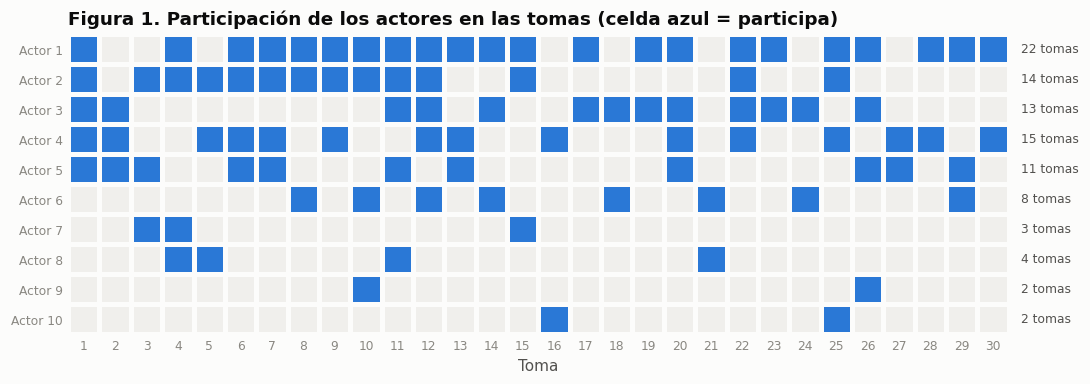

In [2]:
# Figura 1. Vista de los datos: que actor interviene en que toma.

tomas_por_actor = [sum(f[a] for f in TOMAS) for a in range(N_ACTORES)]

fig, ax = plt.subplots(figsize=(10, 3.6))
datos = [[TOMAS[t][a] for t in range(N_TOMAS)] for a in range(N_ACTORES)]   # filas = actores
ax.pcolormesh(datos, cmap=ListedColormap(["#f0efec", C_RECOCIDO]), edgecolors=C_FONDO, linewidth=2)
ax.invert_yaxis()
ax.set_xticks([t + 0.5 for t in range(N_TOMAS)])
ax.set_xticklabels([str(t + 1) for t in range(N_TOMAS)], fontsize=8)
ax.set_yticks([a + 0.5 for a in range(N_ACTORES)])
ax.set_yticklabels([f"Actor {a + 1}" for a in range(N_ACTORES)], fontsize=8)
ax.set_xlabel("Toma")
ax.grid(False)
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
# A la derecha, el numero de tomas de cada actor
for a in range(N_ACTORES):
    ax.text(N_TOMAS + 0.4, a + 0.5, f"{tomas_por_actor[a]} tomas", va="center", fontsize=8, color=C_TINTA2)
ax.set_title("Figura 1. Participación de los actores en las tomas (celda azul = participa)")
plt.tight_layout()
plt.show()

La figura 1 muestra un rasgo importante de los datos: la participación es muy desigual. El actor 1 interviene en 22 de las 30 tomas, mientras que los actores 7, 8, 9 y 10 solo aparecen en 2, 3 o 4. Esta observación se aprovecha más adelante en el algoritmo de ramificación y poda.

(*)¿Cuantas posibilidades hay sin tener en cuenta las restricciones?<br>



¿Cuantas posibilidades hay teniendo en cuenta todas las restricciones.

Respuesta

**Qué es una solución.** Planificar el doblaje es decidir qué tomas se graban juntas el mismo día. El coste no depende del orden de las tomas dentro de un día ni de a qué día llamemos "día 1" o "día 2": solo importa **qué grupo de tomas forma cada día**. Por eso una solución es una **partición del conjunto de las 30 tomas** en grupos no vacíos, y el recuento correcto es un recuento de particiones, no de permutaciones. Contar permutaciones (30!) contaría miles de veces la misma planificación.

**Sin restricciones.** Si no hay límite de tomas por día, cualquier partición de las 30 tomas es una planificación posible (desde grabar todo en un solo día hasta grabar una toma por día). El número de particiones de un conjunto de n elementos es el **número de Bell** B(n), que se calcula con la recurrencia

`B(n) = Σ (k = 0 … n−1)  C(n−1, k) · B(k)`,  con B(0) = 1

La idea de la recurrencia: se fija la toma n y se elige cuántas tomas la acompañan en su día; el resto de tomas se reparte de todas las formas posibles. Para n = 30:

**B(30) = 846.749.014.511.809.332.450.147 ≈ 8,47 · 10²³**

**Con la restricción de 6 tomas por día.** Ahora solo valen las particiones en las que ningún grupo tiene más de 6 tomas. La recurrencia es la misma, pero el día de la toma n solo puede tener de 1 a 6 tomas:

`P(n) = Σ (j = 1 … mín(6, n))  C(n−1, j−1) · P(n−j)`,  con P(0) = 1

donde j es el número de tomas del día que contiene la toma n, y C(n−1, j−1) son las formas de elegir a sus j−1 compañeras. Para n = 30:

**P(30) = 726.391.948.970.868.949.621.309 ≈ 7,26 · 10²³**

Es decir, la restricción solo elimina alrededor del 14 % de las particiones.

**Importante: el número de días no está fijado.** El enunciado dice "no más de 6 tomas por día", no "exactamente 6". Hacen falta como mínimo ⌈30/6⌉ = 5 días, pero también son válidas las planificaciones con 6, 7 o más días, y no se pueden descartar de antemano, porque usar más días puede ser **más barato**. Ejemplo mínimo con 6 tomas, 3 actores y un máximo de 3 tomas por día: las tomas son A, A, B, B, C, C (cada una con un solo actor). Con el mínimo de 2 días, cada día mezcla al menos dos actores y el coste es 4; con 3 días (A, A), (B, B), (C, C) el coste es 3. La celda siguiente lo comprueba.

Si solo se contaran las planificaciones con 5 días completos de 6 tomas, saldrían 30! / ((6!)⁵ · 5!) = 11.423.951.396.577.720 ≈ 1,14 · 10¹⁶, que es únicamente uno de los sumandos del total (el de la primera barra de la figura 2) y representa una fracción de 1,6 · 10⁻⁸ de las soluciones válidas.

In [3]:
# Recuento del espacio de soluciones como particiones de un conjunto.

def numero_de_bell(n):
    # bell[i] = numero de particiones de un conjunto de i elementos
    bell = [1]
    for i in range(1, n + 1):
        bell.append(sum(math.comb(i - 1, k) * bell[k] for k in range(i)))
    return bell[n]

def particiones_validas(n, cap):
    # p[i] = particiones de i tomas en dias de, como mucho, 'cap' tomas.
    # El dia que contiene la toma i tiene j tomas (1 <= j <= cap): se eligen sus j-1 companeras.
    p = [1] + [0] * n
    for i in range(1, n + 1):
        p[i] = sum(math.comb(i - 1, j - 1) * p[i - j] for j in range(1, min(cap, i) + 1))
    return p[n]

def particiones_por_dias(n, cap):
    # tabla[i][d] = formas de repartir i tomas en exactamente d dias (no vacios, de <= cap tomas)
    tabla = [[0] * (n + 1) for _ in range(n + 1)]
    tabla[0][0] = 1
    for i in range(1, n + 1):
        for d in range(1, i + 1):
            tabla[i][d] = sum(math.comb(i - 1, j - 1) * tabla[i - j][d - 1]
                              for j in range(1, min(cap, i) + 1))
    return tabla[n]          # lista indexada por numero de dias

sin_restricciones = numero_de_bell(N_TOMAS)
con_restricciones = particiones_validas(N_TOMAS, MAX_TOMAS_DIA)
por_dias = particiones_por_dias(N_TOMAS, MAX_TOMAS_DIA)

print("Sin restricciones  (numero de Bell B(30)):", miles(sin_restricciones), f"= {sin_restricciones:.3e}")
print("Con restricciones  (dias de <= 6 tomas)  :", miles(con_restricciones), f"= {con_restricciones:.3e}")
print(f"Fraccion de particiones que cumple la restriccion: {100 * con_restricciones / sin_restricciones:.1f} %")
print()
print("Desglose de las soluciones validas por numero de dias:")
for d in range(5, 11):
    print(f"  {d:2d} dias -> {por_dias[d]:.3e}")
print("  ...")
print("  30 dias ->", por_dias[30], "(una toma por dia)")
print("Comprobacion: la suma del desglose coincide con el total ->", sum(por_dias) == con_restricciones)
print()
solo_5_dias = math.factorial(30) // (math.factorial(6) ** 5 * math.factorial(5))
print("Solo 5 dias completos, 30!/((6!)^5 * 5!):", miles(solo_5_dias), "-> coincide con el desglose:", solo_5_dias == por_dias[5])

Sin restricciones  (numero de Bell B(30)): 846.749.014.511.809.332.450.147 = 8.467e+23
Con restricciones  (dias de <= 6 tomas)  : 726.391.948.970.868.949.621.309 = 7.264e+23
Fraccion de particiones que cumple la restriccion: 85.8 %

Desglose de las soluciones validas por numero de dias:
   5 dias -> 1.142e+16
   6 dias -> 2.714e+19
   7 dias -> 1.247e+21
   8 dias -> 1.364e+22
   9 dias -> 6.071e+22
  10 dias -> 1.396e+23
  ...
  30 dias -> 1 (una toma por dia)
Comprobacion: la suma del desglose coincide con el total -> True

Solo 5 dias completos, 30!/((6!)^5 * 5!): 11.423.951.396.577.720 -> coincide con el desglose: True


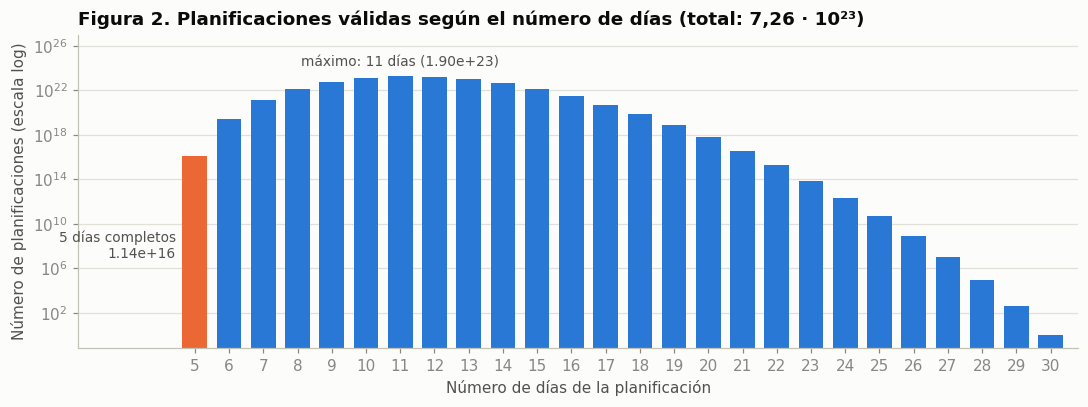

In [4]:
# Figura 2. Soluciones validas segun el numero de dias utilizados (escala logaritmica).

dias_eje = list(range(5, 31))
valores = [float(por_dias[d]) for d in dias_eje]      # a float para poder dibujarlos
d_max = max(dias_eje, key=lambda d: por_dias[d])

fig, ax = plt.subplots(figsize=(10, 3.8))
colores = [C_VORAZ if d == 5 else C_RECOCIDO for d in dias_eje]
ax.bar(dias_eje, valores, color=colores, width=0.72)
ax.set_yscale("log")
ax.set_xticks(dias_eje)
ax.set_xlabel("Número de días de la planificación")
ax.set_ylabel("Número de planificaciones (escala log)")
ax.grid(axis="x", visible=False)
ax.text(4.45, por_dias[5] ** 0.5, f"5 días completos\n{por_dias[5]:.2e}", ha="right", va="center",
        fontsize=9, color=C_TINTA2)
ax.text(d_max, por_dias[d_max] * 8, f"máximo: {d_max} días ({por_dias[d_max]:.2e})", ha="center",
        fontsize=9, color=C_TINTA2)
ax.set_xlim(1.6, 30.8)
ax.set_ylim(top=1e27)
ax.set_title("Figura 2. Planificaciones válidas según el número de días (total: 7,26 · 10²³)")
plt.tight_layout()
plt.show()

Modelo para el espacio de soluciones<br>
(*) ¿Cual es la estructura de datos que mejor se adapta al problema? Argumentalo.(Es posible que hayas elegido una al principio y veas la necesidad de cambiar, arguentalo)

Respuesta

Se han utilizado tres estructuras, cada una para una necesidad distinta. La elección cambió a lo largo del trabajo y se explica por qué.

**1. La solución: lista de días (lista de listas).** Una planificación es una partición de las tomas, así que se representa como una lista de días, donde cada día es la lista de los índices de sus tomas. Es la traducción directa del modelo: la restricción de capacidad se comprueba con `len(dia) <= 6` y no hay forma de representar algo que no sea una partición si cada toma aparece una sola vez. Es la estructura que usan la fuerza bruta, el algoritmo voraz y la salida de todos los métodos.

**2. Los actores de una toma: máscara de bits (un entero).** En la primera versión cada toma se guardaba como un conjunto (`set`) de actores y los actores de un día se obtenían uniendo conjuntos. Funciona, pero la operación "unir y contar actores distintos" se ejecuta millones de veces en la búsqueda exhaustiva. Como solo hay 10 actores, un conjunto de actores cabe en un entero de 10 bits: el bit a vale 1 si el actor a participa. Con esto:

- unir los actores de dos tomas es un OR (`x | y`),
- los actores **nuevos** que aporta una toma a un día son `toma & ~dia`,
- contar actores es contar bits a 1.

Son operaciones sobre un único entero, mucho más rápidas que las equivalentes con conjuntos, y el código se mantiene corto.

**3. Para el recocido simulado: vector de asignación más contadores.** El recocido no construye soluciones, sino que modifica una solución existente miles de veces (mover una toma de día, intercambiar dos tomas). Con la lista de listas, cada movimiento obligaría a buscar la toma en su día y a recalcular el coste completo. Por eso se cambia a:

- `dia_de[t]`: el día asignado a la toma t (vector de longitud n),
- `cuenta[d][a]`: en cuántas tomas del día d interviene el actor a,
- `tam[d]`: número de tomas del día d.

Con los contadores, quitar o poner una toma actualiza el coste mirando solo los actores de esa toma: si un contador pasa de 1 a 0, ese actor deja de venir ese día (coste −1); si pasa de 0 a 1, tiene que venir (coste +1). El coste de un movimiento pasa de ser proporcional a todo el plan a ser proporcional al número de actores de una toma.

Al terminar, el recocido convierte su resultado otra vez a lista de días, de modo que todos los algoritmos devuelven el mismo tipo de solución.

In [5]:
# Estructuras de datos basicas.

def a_mascaras(matriz):
    # Convierte cada fila 0/1 de la matriz en un entero: el bit 'a' vale 1 si el actor 'a' participa.
    return [sum(1 << a for a, participa in enumerate(fila) if participa) for fila in matriz]

def n_bits(x):
    # Numero de bits a 1 = numero de actores del conjunto representado por x
    return bin(x).count("1")

def actores_de(mascara):
    # Lista de actores (numerados desde 1) contenidos en una mascara. Solo para mostrar resultados.
    return [a + 1 for a in range(mascara.bit_length()) if (mascara >> a) & 1]

def mascara_del_dia(dia, masc):
    # Actores citados un dia = union (OR) de los actores de sus tomas
    union = 0
    for t in dia:
        union |= masc[t]
    return union

def es_valido(plan, n_tomas, cap):
    # Un plan es valido si es una particion de las tomas y ningun dia supera la capacidad
    todas = sorted(t for dia in plan for t in dia)
    return todas == list(range(n_tomas)) and all(1 <= len(dia) <= cap for dia in plan)

MASC = a_mascaras(TOMAS)

print("Toma 1 -> fila", TOMAS[0], "-> mascara", MASC[0], f"({MASC[0]:010b}) -> actores", actores_de(MASC[0]))
print("Toma 2 -> fila", TOMAS[1], "-> mascara", MASC[1], f"({MASC[1]:010b}) -> actores", actores_de(MASC[1]))
print("Actores de las tomas 1 y 2 juntas:", actores_de(MASC[0] | MASC[1]))
print("Actores nuevos que aporta la toma 3 a ese dia:", actores_de(MASC[2] & ~(MASC[0] | MASC[1])))
print()

# Ejemplo de planificacion: las tomas en el orden del enunciado, de 6 en 6
plan_secuencial = [list(range(i, i + 6)) for i in range(0, N_TOMAS, 6)]
print("Plan secuencial valido:", es_valido(plan_secuencial, N_TOMAS, MAX_TOMAS_DIA))
for i, dia in enumerate(plan_secuencial, 1):
    actores = actores_de(mascara_del_dia(dia, MASC))
    print(f"  Dia {i} -> tomas {[t + 1 for t in dia]} -> actores {actores} ({len(actores)})")

Toma 1 -> fila [1, 1, 1, 1, 1, 0, 0, 0, 0, 0] -> mascara 31 (0000011111) -> actores [1, 2, 3, 4, 5]
Toma 2 -> fila [0, 0, 1, 1, 1, 0, 0, 0, 0, 0] -> mascara 28 (0000011100) -> actores [3, 4, 5]
Actores de las tomas 1 y 2 juntas: [1, 2, 3, 4, 5]
Actores nuevos que aporta la toma 3 a ese dia: [7]

Plan secuencial valido: True
  Dia 1 -> tomas [1, 2, 3, 4, 5, 6] -> actores [1, 2, 3, 4, 5, 7, 8] (7)
  Dia 2 -> tomas [7, 8, 9, 10, 11, 12] -> actores [1, 2, 3, 4, 5, 6, 8, 9] (8)
  Dia 3 -> tomas [13, 14, 15, 16, 17, 18] -> actores [1, 2, 3, 4, 5, 6, 7, 10] (8)
  Dia 4 -> tomas [19, 20, 21, 22, 23, 24] -> actores [1, 2, 3, 4, 5, 6, 8] (7)
  Dia 5 -> tomas [25, 26, 27, 28, 29, 30] -> actores [1, 2, 3, 4, 5, 6, 9, 10] (8)


Según el modelo para el espacio de soluciones<br>
(*)¿Cual es la función objetivo?

(*)¿Es un problema de maximización o minimización?

Respuesta

**Función objetivo.** Todos los actores cobran lo mismo por cada día que acuden al estudio, sea cual sea el número de tomas que graben. Por tanto, el coste de un día es el número de actores distintos que intervienen en alguna de sus tomas, y el coste de una planificación P es la suma de los costes de sus días:

`coste(P) = Σ (día d de P)  | unión de los actores de las tomas de d |`

La unidad es "actor-día": cada unidad es un desplazamiento pagado.

**Es un problema de minimización**: se busca la planificación válida (ningún día con más de 6 tomas) con el menor coste posible. Intuitivamente, conviene agrupar en un mismo día las tomas que comparten actores.

**Una cota inferior sencilla.** Un actor que interviene en k tomas necesita venir al menos ⌈k/6⌉ días, porque en un día caben 6 tomas como mucho. Sumando para todos los actores se obtiene un valor por debajo del cual no puede bajar ninguna planificación. En el problema real esa cota vale 21. No dice que 21 sea alcanzable, pero permite situar cualquier resultado.

In [6]:
# Funcion objetivo: coste total de una planificacion (numero de actores-dia).

def coste(plan, masc):
    return sum(n_bits(mascara_del_dia(dia, masc)) for dia in plan)

def cota_inferior_simple(masc, n_actores, cap):
    # Cada actor necesita al menos techo(tomas del actor / cap) dias
    total = 0
    for a in range(n_actores):
        tomas_del_actor = sum((x >> a) & 1 for x in masc)
        total += math.ceil(tomas_del_actor / cap)
    return total

COSTE_SECUENCIAL = coste(plan_secuencial, MASC)
print("Coste del plan secuencial:", COSTE_SECUENCIAL)
print("Cota inferior simple del problema real:", cota_inferior_simple(MASC, N_ACTORES, MAX_TOMAS_DIA))

Coste del plan secuencial: 38
Cota inferior simple del problema real: 21


Diseña un algoritmo para resolver el problema por fuerza bruta

Respuesta

La fuerza bruta genera **todas** las particiones válidas de las tomas, calcula el coste de cada una y se queda con la mejor. Garantiza el óptimo porque examina el espacio de soluciones completo.

Las particiones se generan con retroceso (backtracking), tomando las tomas una a una. Para la toma i hay dos tipos de decisión:

- colocarla en alguno de los días ya abiertos que tenga hueco, o
- abrir un día nuevo con ella.

Cuando todas las tomas están colocadas se tiene una partición completa y se evalúa. Como los días nuevos solo se abren "al final", cada partición se genera exactamente una vez (no se repite la misma planificación con los días en otro orden). Esto se comprueba en la celda: el número de soluciones evaluadas coincide con el recuento P(n) calculado antes con la recurrencia, lo que valida a la vez el algoritmo y el recuento.

Por su coste, solo se puede ejecutar sobre versiones reducidas del problema.

In [7]:
# Fuerza bruta: busqueda exhaustiva de todas las particiones validas (retroceso).

def fuerza_bruta(masc, cap):
    n = len(masc)
    mejor = {"coste": None, "plan": None, "evaluadas": 0}
    plan = []                                   # particion en construccion

    def colocar(i):
        if i == n:                              # todas las tomas colocadas: solucion completa
            mejor["evaluadas"] += 1
            c = coste(plan, masc)
            if mejor["coste"] is None or c < mejor["coste"]:
                mejor["coste"] = c
                mejor["plan"] = [dia[:] for dia in plan]
            return
        # Opcion 1: meter la toma i en un dia ya abierto que tenga hueco
        for dia in plan:
            if len(dia) < cap:
                dia.append(i)
                colocar(i + 1)
                dia.pop()                       # deshacer (retroceso)
        # Opcion 2: abrir un dia nuevo con la toma i
        plan.append([i])
        colocar(i + 1)
        plan.pop()

    colocar(0)
    return mejor["plan"], mejor["coste"], mejor["evaluadas"]

# 1) Version reducida del problema real: las 10 primeras tomas, con la capacidad real de 6 por dia
plan_fb, coste_fb, evaluadas = fuerza_bruta(MASC[:10], MAX_TOMAS_DIA)
print("Version reducida (10 primeras tomas, maximo 6 por dia)")
for i, dia in enumerate(plan_fb, 1):
    print(f"  Dia {i} -> tomas {[t + 1 for t in dia]} -> actores {actores_de(mascara_del_dia(dia, MASC))}")
print("  Coste optimo:", coste_fb)
print("  Soluciones evaluadas:", miles(evaluadas), "| recuento por la recurrencia:", miles(particiones_validas(10, 6)))
print()

# 2) El ejemplo del apartado de recuento: usar mas dias que el minimo puede ser mas barato
ejemplo = [0b001, 0b001, 0b010, 0b010, 0b100, 0b100]       # tomas A, A, B, B, C, C
plan_2_dias = [[0, 1, 2], [3, 4, 5]]
plan_ej, coste_ej, _ = fuerza_bruta(ejemplo, 3)
print("Ejemplo A, A, B, B, C, C con maximo 3 tomas por dia")
print("  Plan con el minimo de dias", plan_2_dias, "-> coste", coste(plan_2_dias, ejemplo))
print("  Optimo por fuerza bruta   ", plan_ej, "-> coste", coste_ej, f"({len(plan_ej)} dias)")

Version reducida (10 primeras tomas, maximo 6 por dia)
  Dia 1 -> tomas [1, 2, 3, 4, 5, 6] -> actores [1, 2, 3, 4, 5, 7, 8]
  Dia 2 -> tomas [7, 8, 9, 10] -> actores [1, 2, 4, 5, 6, 9]
  Coste optimo: 13
  Soluciones evaluadas: 115.274 | recuento por la recurrencia: 115.274

Ejemplo A, A, B, B, C, C con maximo 3 tomas por dia
  Plan con el minimo de dias [[0, 1, 2], [3, 4, 5]] -> coste 4
  Optimo por fuerza bruta    [[0, 1], [2, 3], [4, 5]] -> coste 3 (3 dias)


Calcula la complejidad del algoritmo por fuerza bruta

Respuesta

El algoritmo visita una hoja del árbol de búsqueda por cada partición válida, y en cada hoja evalúa el coste recorriendo las n tomas. Por tanto:

`T(n) = O( n · P(n) )`

donde P(n) es el número de particiones en días de 6 tomas como mucho, calculado en el primer apartado. P(n) está acotado superiormente por el número de Bell B(n) y se queda muy cerca de él (para n = 30 es el 86 % de B(30)). Los números de Bell crecen **más rápido que cualquier exponencial** cⁿ (aunque más despacio que n!), así que la complejidad es superexponencial.

Añadir una sola toma multiplica el trabajo por un factor cada vez mayor: de 10 a 11 tomas se multiplica por 5,8 y de 11 a 12 por 6,2. La celda siguiente mide el tiempo real en versiones reducidas, comprueba que las soluciones evaluadas coinciden con P(n) y extrapola, con la velocidad medida en esta máquina, cuánto tardaría el problema completo.

In [8]:
# Medida empirica de la fuerza bruta en versiones reducidas del problema real (capacidad real: 6).

medidas_fb = []          # (n, soluciones evaluadas, segundos)
print(" n | soluciones evaluadas | recurrencia P(n) | coinciden | tiempo (s)")
print("---+----------------------+------------------+-----------+-----------")
for n in range(4, 12):
    inicio = time.perf_counter()
    _, _, evaluadas = fuerza_bruta(MASC[:n], MAX_TOMAS_DIA)
    segundos = time.perf_counter() - inicio
    medidas_fb.append((n, evaluadas, segundos))
    teorico = particiones_validas(n, MAX_TOMAS_DIA)
    print(f"{n:2d} | {miles(evaluadas):>20} | {miles(teorico):>16} | {str(evaluadas == teorico):>9} | {segundos:9.3f}")

# Velocidad medida (soluciones por segundo) en la instancia mas grande ejecutada
n_ult, eval_ult, seg_ult = medidas_fb[-1]
velocidad = eval_ult / seg_ult
segundos_30 = particiones_validas(30, MAX_TOMAS_DIA) / velocidad
anios_30 = segundos_30 / (3600 * 24 * 365)
print()
print(f"Velocidad medida: {velocidad:,.0f} soluciones por segundo".replace(",", "."))
print(f"Extrapolacion a 30 tomas: {anios_30:.1e} años (la edad del universo es 1,4e10 años)")

 n | soluciones evaluadas | recurrencia P(n) | coinciden | tiempo (s)
---+----------------------+------------------+-----------+-----------
 4 |                   15 |               15 |      True |     0.000
 5 |                   52 |               52 |      True |     0.000
 6 |                  203 |              203 |      True |     0.001
 7 |                  876 |              876 |      True |     0.002
 8 |                4.131 |            4.131 |      True |     0.018
 9 |               21.065 |           21.065 |      True |     0.070
10 |              115.274 |          115.274 |      True |     0.440
11 |              672.673 |          672.673 |      True |     2.368

Velocidad medida: 284.020 soluciones por segundo
Extrapolacion a 30 tomas: 8.1e+10 años (la edad del universo es 1,4e10 años)


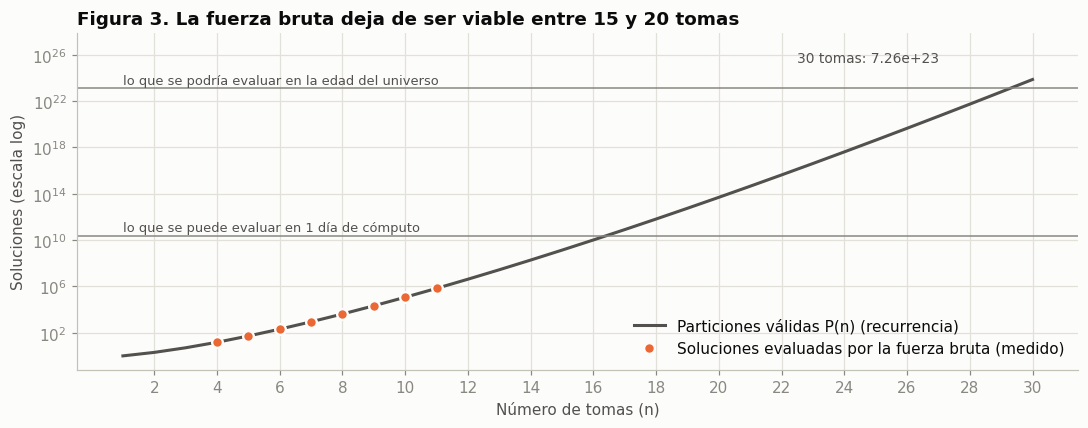

In [9]:
# Figura 3. Crecimiento del espacio de busqueda de la fuerza bruta (escala logaritmica).

ns = list(range(1, 31))
teoricos = [float(particiones_validas(n, MAX_TOMAS_DIA)) for n in ns]
en_un_dia = velocidad * 3600 * 24                      # soluciones evaluables en un dia de computo
en_edad_universo = velocidad * 3600 * 24 * 365 * 1.38e10

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ns, teoricos, color=C_FB, label="Particiones válidas P(n) (recurrencia)")
ax.plot([m[0] for m in medidas_fb], [m[1] for m in medidas_fb], "o", color=C_VORAZ, markersize=7,
        markeredgecolor=C_FONDO, markeredgewidth=1.5, label="Soluciones evaluadas por la fuerza bruta (medido)")
ax.axhline(en_un_dia, color=C_SUAVE, linewidth=1)
ax.text(1, en_un_dia * 2.5, "lo que se puede evaluar en 1 día de cómputo", fontsize=8.5, color=C_TINTA2)
ax.axhline(en_edad_universo, color=C_SUAVE, linewidth=1)
ax.text(1, en_edad_universo * 2.5, "lo que se podría evaluar en la edad del universo", fontsize=8.5, color=C_TINTA2)
ax.annotate(f"30 tomas: {teoricos[-1]:.2e}", xy=(30, teoricos[-1]), xytext=(22.5, teoricos[-1] * 30),
            fontsize=9, color=C_TINTA2)
ax.set_yscale("log")
ax.set_xlabel("Número de tomas (n)")
ax.set_ylabel("Soluciones (escala log)")
ax.set_xticks(range(2, 31, 2))
ax.set_ylim(top=teoricos[-1] * 1e4)
ax.legend(loc="lower right")
ax.set_title("Figura 3. La fuerza bruta deja de ser viable entre 15 y 20 tomas")
plt.tight_layout()
plt.show()

(*)Diseña un algoritmo que mejore la complejidad del algortimo por fuerza bruta. Argumenta porque crees que mejora el algoritmo por fuerza bruta

Respuesta

Se proponen **dos algoritmos complementarios**, porque mejoran a la fuerza bruta de dos maneras distintas, y se mantiene el algoritmo voraz como punto de partida de ambos.

| | Voraz | Ramificación y poda | Recocido simulado |
|---|---|---|---|
| Tipo | heurística constructiva | exacto | metaheurística |
| ¿Garantiza el óptimo? | no | **sí** | no |
| Complejidad | polinómica | exponencial en el peor caso | **polinómica** |
| Papel en el trabajo | solución inicial | óptimo del problema real | tamaños grandes |

### Paso 0. Algoritmo voraz (solución inicial)

Construye la planificación día a día: abre un día con una toma semilla (la de más actores) y lo completa añadiendo cada vez la toma pendiente que **menos actores nuevos** aporta. La variante con multiarranque repite la construcción probando cada toma como primera semilla. Es muy rápido, pero cada decisión es definitiva y usa un único criterio, por lo que se queda en soluciones mejorables: en el problema real obtiene 31 (simple) y 29 (multiarranque). Aquí solo se usa para dar un buen punto de partida a los otros dos algoritmos.

### Algoritmo 1. Ramificación y poda (exacto)

Parte del mismo árbol de búsqueda que la fuerza bruta (cada toma va a un día abierto o abre uno nuevo), pero **no lo recorre entero**. Usa tres ideas:

**a) Cota inferior en cada nodo.** Con parte de las tomas ya colocadas, se calcula cuánto va a costar, *como mínimo*, colocar el resto. Para cada actor a:

- quedan r tomas suyas sin colocar;
- en los días donde ya está citado quedan f huecos libres: como mucho f de esas tomas le salen "gratis";
- las r − f restantes tendrán que ir a días en los que todavía no está citado, y cada uno de esos días admite como mucho 6 tomas, así que tendrá que venir al menos ⌈(r − f) / 6⌉ días más.

La suma para todos los actores es una cota inferior válida del coste que falta, porque nunca sobreestima.

**b) Poda.** Si *coste acumulado + cota inferior ≥ mejor coste conocido*, ninguna solución de esa rama puede mejorar la mejor solución que ya se tiene, y la rama entera se descarta sin explorarla. El mejor coste conocido se inicializa con la solución del voraz, de modo que se poda desde el primer nodo.

**c) Heurística de ordenación: primero las tomas con actores poco frecuentes.** El orden en que se colocan las tomas no afecta al resultado, pero sí, y mucho, al tamaño del árbol. Se colocan primero las tomas en las que participa algún actor que aparece en muy pocas tomas (los actores 9, 10, 7 y 8 de la figura 1). Así las decisiones sobre esos actores se toman al principio, cuando hay pocas ramas, y la cota se vuelve ajustada muy pronto. Además, en cada nodo se prueban antes los días donde la toma aporta menos actores nuevos, para encontrar pronto soluciones buenas que refuercen la poda. Con el orden original, o colocando primero las tomas con más actores, el mismo algoritmo no termina dentro de un límite de 2 millones de nodos en el problema real, más de 25 veces el trabajo que necesita con el orden propuesto (se mide en el apartado de complejidad).

**Por qué mejora a la fuerza bruta.** Sigue siendo exacto: solo descarta ramas que demostrablemente no contienen nada mejor, así que al terminar el resultado es el óptimo. Pero en lugar de 7,26 · 10²³ soluciones, en el problema real explora del orden de 10⁵ nodos y termina en menos de un segundo. Su limitación es que en el peor caso sigue siendo exponencial: la poda no tiene garantía de funcionar siempre igual de bien.

### Algoritmo 2. Recocido simulado (metaheurística)

Para los tamaños en los que ramificación y poda no termina, se usa el recocido simulado visto en la asignatura. Parte de la solución del voraz y la va modificando:

- **Dos vecindarios.** En cada iteración se elige al azar entre *mover* una toma a otro día con hueco (cambia el tamaño de los días e incluso su número, porque puede usar días vacíos) e *intercambiar* dos tomas de días distintos (imprescindible cuando los días están llenos y no se puede mover nada). Combinar los dos permite cambiar tanto el contenido de los días como su tamaño y su número (hasta dos días más que la solución inicial).
- **Criterio de aceptación.** Si el movimiento no empeora, se acepta. Si empeora el coste en Δ, se acepta con probabilidad e^(−Δ/T). Esto es lo que lo diferencia de una búsqueda local: puede salir de óptimos locales aceptando empeorar temporalmente.
- **Enfriamiento geométrico.** La temperatura T baja multiplicándose por una constante en cada iteración, de T = 1,5 (se acepta la mitad de los empeoramientos de 1 unidad) a T = 0,05 (prácticamente ninguno).
- **Reinicios.** Se ejecuta varias veces desde soluciones voraces distintas y se conserva la mejor.
- **Evaluación incremental.** Gracias a los contadores `cuenta[d][a]`, el efecto de un movimiento se calcula mirando solo los actores de las tomas afectadas.

**Por qué mejora a la fuerza bruta.** El número de iteraciones lo fija quien lo ejecuta, no el tamaño del espacio de soluciones, así que el coste es polinómico. A cambio no garantiza el óptimo; por eso se mide experimentalmente a qué distancia se queda.

In [10]:
# Paso 0. Algoritmo voraz constructivo (se usa como solucion inicial de los otros dos algoritmos).

def voraz(masc, cap, semilla=None):
    # 'semilla' es la toma con la que se abre el primer dia (si no se indica, la de mas actores)
    pendientes = list(range(len(masc)))
    plan = []
    while pendientes:
        if semilla is not None:
            primera, semilla = semilla, None
        else:
            primera = max(pendientes, key=lambda t: n_bits(masc[t]))
        dia = [primera]
        actores_dia = masc[primera]
        pendientes.remove(primera)
        # Completar el dia con la toma que menos actores nuevos aporta
        while len(dia) < cap and pendientes:
            elegida = min(pendientes, key=lambda t: n_bits(masc[t] & ~actores_dia))
            dia.append(elegida)
            actores_dia |= masc[elegida]
            pendientes.remove(elegida)
        plan.append(sorted(dia))
    return plan

def voraz_multiarranque(masc, cap):
    # Prueba cada toma como primera semilla y se queda con el mejor plan
    mejor_plan, mejor_coste = None, None
    for semilla in range(len(masc)):
        plan = voraz(masc, cap, semilla)
        c = coste(plan, masc)
        if mejor_coste is None or c < mejor_coste:
            mejor_plan, mejor_coste = plan, c
    return mejor_plan, mejor_coste

plan_voraz = voraz(MASC, MAX_TOMAS_DIA)
plan_voraz_multi, COSTE_VORAZ_MULTI = voraz_multiarranque(MASC, MAX_TOMAS_DIA)
COSTE_VORAZ = coste(plan_voraz, MASC)
print("Voraz simple        -> coste", COSTE_VORAZ)
print("Voraz multiarranque -> coste", COSTE_VORAZ_MULTI)

Voraz simple        -> coste 31
Voraz multiarranque -> coste 29


In [11]:
# Algoritmo 1. Ramificacion y poda (exacto).

def ramificacion_y_poda(masc, n_actores, cap, plan_inicial=None, max_nodos=None, orden="poco_frecuentes"):
    """Devuelve (plan, coste, nodos explorados, optimo_demostrado).
    plan_inicial: solucion heuristica que da la primera cota superior (opcional).
    max_nodos:    limite de nodos; si se alcanza, el resultado deja de estar demostrado como optimo.
    orden:        'poco_frecuentes' (propuesto), 'mas_actores' u 'original' (para comparar)."""
    n = len(masc)

    # --- (c) Heuristica de ordenacion de las tomas ---
    frecuencia = [sum((x >> a) & 1 for x in masc) for a in range(n_actores)]

    def clave_poco_frecuentes(t):
        actores = [a for a in range(n_actores) if (masc[t] >> a) & 1]
        # 1º el actor menos frecuente de la toma; a igualdad, la toma con mas actores
        return (min((frecuencia[a] for a in actores), default=0), -len(actores), masc[t])

    if orden == "poco_frecuentes":
        indices = sorted(range(n), key=clave_poco_frecuentes)
    elif orden == "mas_actores":
        indices = sorted(range(n), key=lambda t: (-n_bits(masc[t]), masc[t]))
    else:
        indices = list(range(n))
    m_ord = [masc[t] for t in indices]          # mascaras en el orden de colocacion

    # quedan[i][a] = tomas aun sin colocar (posiciones i..n-1) en las que interviene el actor a
    quedan = [[0] * n_actores for _ in range(n + 1)]
    for i in range(n - 1, -1, -1):
        for a in range(n_actores):
            quedan[i][a] = quedan[i + 1][a] + ((m_ord[i] >> a) & 1)

    # Mejor solucion conocida (cota superior). Se inicializa con la solucion heuristica.
    mejor = {"coste": math.inf, "asignacion": None, "nodos": 0, "completo": True}
    if plan_inicial is not None:
        mejor["coste"] = coste(plan_inicial, masc)

    dia_actores = []            # mascara de actores de cada dia abierto
    dia_tam = []                # numero de tomas de cada dia abierto
    asignacion = [0] * n        # dia asignado a cada toma (en el orden de colocacion)

    def cota_inferior(i):
        # (a) Minimo de actores-dia adicionales necesarios para colocar las tomas i..n-1
        total = 0
        for a in range(n_actores):
            r = quedan[i][a]                    # tomas pendientes del actor a
            if r:
                f = 0                           # huecos libres en dias donde 'a' ya esta citado
                for k in range(len(dia_actores)):
                    if (dia_actores[k] >> a) & 1:
                        f += cap - dia_tam[k]
                if r > f:
                    total += (r - f + cap - 1) // cap       # techo((r - f) / cap)
        return total

    def explorar(i, coste_parcial):
        if not mejor["completo"]:
            return
        mejor["nodos"] += 1
        if max_nodos is not None and mejor["nodos"] > max_nodos:
            mejor["completo"] = False           # se abandona la busqueda: ya no hay garantia
            return
        if i == n:                              # solucion completa y mejor que la conocida
            if coste_parcial < mejor["coste"]:
                mejor["coste"] = coste_parcial
                mejor["asignacion"] = asignacion[:]
            return
        # (b) Poda: esta rama no puede mejorar la mejor solucion conocida
        if coste_parcial + cota_inferior(i) >= mejor["coste"]:
            return
        toma = m_ord[i]
        # Dias abiertos con hueco, probando antes aquellos donde la toma aporta menos actores nuevos
        candidatos = sorted((n_bits(toma & ~dia_actores[k]), k)
                            for k in range(len(dia_actores)) if dia_tam[k] < cap)
        for nuevos, k in candidatos:
            anterior = dia_actores[k]
            dia_actores[k] |= toma
            dia_tam[k] += 1
            asignacion[i] = k
            explorar(i + 1, coste_parcial + nuevos)
            dia_actores[k] = anterior           # deshacer
            dia_tam[k] -= 1
        # Abrir un dia nuevo con esta toma
        dia_actores.append(toma)
        dia_tam.append(1)
        asignacion[i] = len(dia_actores) - 1
        explorar(i + 1, coste_parcial + n_bits(toma))
        dia_actores.pop()
        dia_tam.pop()

    explorar(0, 0)

    if mejor["asignacion"] is None:             # no se ha encontrado nada mejor que el plan inicial
        plan = plan_inicial
    else:
        plan = [[] for _ in range(max(mejor["asignacion"]) + 1)]
        for i, k in enumerate(mejor["asignacion"]):
            plan[k].append(indices[i])          # se deshace la reordenacion de las tomas
        plan = [sorted(dia) for dia in plan]
    return plan, mejor["coste"], mejor["nodos"], mejor["completo"]

inicio = time.perf_counter()
plan_byp, COSTE_OPTIMO, NODOS_BYP, demostrado = ramificacion_y_poda(
    MASC, N_ACTORES, MAX_TOMAS_DIA, plan_inicial=plan_voraz_multi)
tiempo_byp = time.perf_counter() - inicio

print("RAMIFICACION Y PODA SOBRE EL PROBLEMA REAL (30 tomas)")
for i, dia in enumerate(plan_byp, 1):
    actores = actores_de(mascara_del_dia(dia, MASC))
    print(f"  Dia {i} -> tomas {[t + 1 for t in dia]} -> actores {actores} ({len(actores)})")
print("Coste:", COSTE_OPTIMO, "| plan valido:", es_valido(plan_byp, N_TOMAS, MAX_TOMAS_DIA),
      "| coincide con coste(plan):", coste(plan_byp, MASC) == COSTE_OPTIMO)
print("Optimo demostrado (busqueda completada):", demostrado)
print("Nodos explorados:", miles(NODOS_BYP), f"| tiempo: {tiempo_byp:.2f} s")

RAMIFICACION Y PODA SOBRE EL PROBLEMA REAL (30 tomas)
  Dia 1 -> tomas [1, 10, 12, 16, 25, 26] -> actores [1, 2, 3, 4, 5, 6, 9, 10] (8)
  Dia 2 -> tomas [3, 4, 8, 15, 21, 29] -> actores [1, 2, 5, 6, 7, 8] (6)
  Dia 3 -> tomas [5, 6, 7, 9, 11, 22] -> actores [1, 2, 3, 4, 5, 8] (6)
  Dia 4 -> tomas [14, 17, 18, 19, 23, 24] -> actores [1, 3, 6] (3)
  Dia 5 -> tomas [2, 13, 20, 27, 28, 30] -> actores [1, 3, 4, 5] (4)
Coste: 27 | plan valido: True | coincide con coste(plan): True
Optimo demostrado (busqueda completada): True
Nodos explorados: 74.598 | tiempo: 0.58 s


In [12]:
# Algoritmo 2. Recocido simulado con dos vecindarios (mover / intercambiar) y evaluacion incremental.

def recocido_simulado(masc, n_actores, cap, plan_inicial, iteraciones=None, t_inicial=1.5, t_final=0.05,
                      semilla=None, dias_extra=2, guardar_historial=False):
    """Devuelve (plan, coste, historial). El historial guarda (iteracion, coste actual, mejor coste)."""
    rng = random.Random(semilla)
    n = len(masc)
    if iteraciones is None:
        iteraciones = 3000 * n
    actores = [[a for a in range(n_actores) if (x >> a) & 1] for x in masc]   # actores de cada toma
    n_dias = len(plan_inicial) + dias_extra       # se dejan dias vacios disponibles

    dia_de = [0] * n                              # dia asignado a cada toma
    cuenta = [[0] * n_actores for _ in range(n_dias)]   # cuenta[d][a]: tomas del dia d con el actor a
    tam = [0] * n_dias                            # numero de tomas de cada dia

    def poner(t, d):
        # Pone la toma t en el dia d y devuelve cuanto sube el coste
        cambio = 0
        for a in actores[t]:
            if cuenta[d][a] == 0:
                cambio += 1                       # el actor 'a' tiene que venir un dia mas
            cuenta[d][a] += 1
        tam[d] += 1
        dia_de[t] = d
        return cambio

    def quitar(t, d):
        # Quita la toma t del dia d y devuelve cuanto cambia el coste (0 o negativo)
        cambio = 0
        for a in actores[t]:
            cuenta[d][a] -= 1
            if cuenta[d][a] == 0:
                cambio -= 1                       # el actor 'a' ya no viene ese dia
        tam[d] -= 1
        return cambio

    actual = 0
    for d, dia in enumerate(plan_inicial):
        for t in dia:
            actual += poner(t, d)
    mejor, mejor_dia_de = actual, dia_de[:]

    alfa = (t_final / t_inicial) ** (1.0 / iteraciones)   # factor de enfriamiento geometrico
    temperatura = t_inicial
    historial = []

    for it in range(iteraciones):
        if rng.random() < 0.5:
            # --- Vecindario 1: MOVER una toma a otro dia con hueco ---
            t = rng.randrange(n)
            origen, destino = dia_de[t], rng.randrange(n_dias)
            if destino != origen and tam[destino] < cap:
                delta = quitar(t, origen) + poner(t, destino)
                if delta <= 0 or rng.random() < math.exp(-delta / temperatura):
                    actual += delta                               # se acepta
                else:
                    quitar(t, destino)                            # se rechaza: deshacer
                    poner(t, origen)
        else:
            # --- Vecindario 2: INTERCAMBIAR dos tomas de dias distintos ---
            t1, t2 = rng.randrange(n), rng.randrange(n)
            d1, d2 = dia_de[t1], dia_de[t2]
            if d1 != d2 and masc[t1] != masc[t2]:
                delta = quitar(t1, d1) + quitar(t2, d2) + poner(t1, d2) + poner(t2, d1)
                if delta <= 0 or rng.random() < math.exp(-delta / temperatura):
                    actual += delta
                else:
                    quitar(t1, d2)
                    quitar(t2, d1)
                    poner(t1, d1)
                    poner(t2, d2)
        if actual < mejor:
            mejor, mejor_dia_de = actual, dia_de[:]
        if guardar_historial and it % 100 == 0:
            historial.append((it, actual, mejor))
        temperatura *= alfa

    # Se devuelve la mejor solucion vista, convertida a lista de dias (sin dias vacios)
    plan = [[] for _ in range(n_dias)]
    for t, d in enumerate(mejor_dia_de):
        plan[d].append(t)
    return [dia for dia in plan if dia], mejor, historial

def recocido_con_reinicios(masc, n_actores, cap, reinicios=3, semilla=0):
    # Varias ejecuciones desde soluciones voraces con distinta semilla; se conserva la mejor
    rng = random.Random(semilla)
    mejor_plan, mejor_coste = None, None
    for _ in range(reinicios):
        inicial = voraz(masc, cap, semilla=rng.randrange(len(masc)))
        plan, c, _ = recocido_simulado(masc, n_actores, cap, inicial, semilla=rng.randrange(10 ** 9))
        if mejor_coste is None or c < mejor_coste:
            mejor_plan, mejor_coste = plan, c
    return mejor_plan, mejor_coste

inicio = time.perf_counter()
plan_rs, COSTE_RS = recocido_con_reinicios(MASC, N_ACTORES, MAX_TOMAS_DIA)
tiempo_rs = time.perf_counter() - inicio

print("RECOCIDO SIMULADO SOBRE EL PROBLEMA REAL (30 tomas, 3 reinicios)")
for i, dia in enumerate(plan_rs, 1):
    actores = actores_de(mascara_del_dia(dia, MASC))
    print(f"  Dia {i} -> tomas {[t + 1 for t in dia]} -> actores {actores} ({len(actores)})")
print("Coste:", COSTE_RS, "| plan valido:", es_valido(plan_rs, N_TOMAS, MAX_TOMAS_DIA),
      "| coincide con coste(plan):", coste(plan_rs, MASC) == COSTE_RS, f"| tiempo: {tiempo_rs:.2f} s")

# Robustez: 20 ejecuciones independientes de una sola pasada (sin reinicios), con semillas distintas
resultados = [recocido_simulado(MASC, N_ACTORES, MAX_TOMAS_DIA, plan_voraz, semilla=s)[1] for s in range(20)]
print("20 ejecuciones de una sola pasada ->", {c: resultados.count(c) for c in sorted(set(resultados))},
      "(coste: numero de ejecuciones)")

RECOCIDO SIMULADO SOBRE EL PROBLEMA REAL (30 tomas, 3 reinicios)
  Dia 1 -> tomas [14, 17, 18, 19, 23, 24] -> actores [1, 3, 6] (3)
  Dia 2 -> tomas [3, 4, 8, 15, 21, 29] -> actores [1, 2, 5, 6, 7, 8] (6)
  Dia 3 -> tomas [2, 5, 9, 11, 20, 22] -> actores [1, 2, 3, 4, 5, 8] (6)
  Dia 4 -> tomas [1, 7, 10, 12, 26, 28] -> actores [1, 2, 3, 4, 5, 6, 9] (7)
  Dia 5 -> tomas [6, 13, 16, 25, 27, 30] -> actores [1, 2, 4, 5, 10] (5)
Coste: 27 | plan valido: True | coincide con coste(plan): True | tiempo: 0.78 s
20 ejecuciones de una sola pasada -> {27: 18, 28: 2} (coste: numero de ejecuciones)


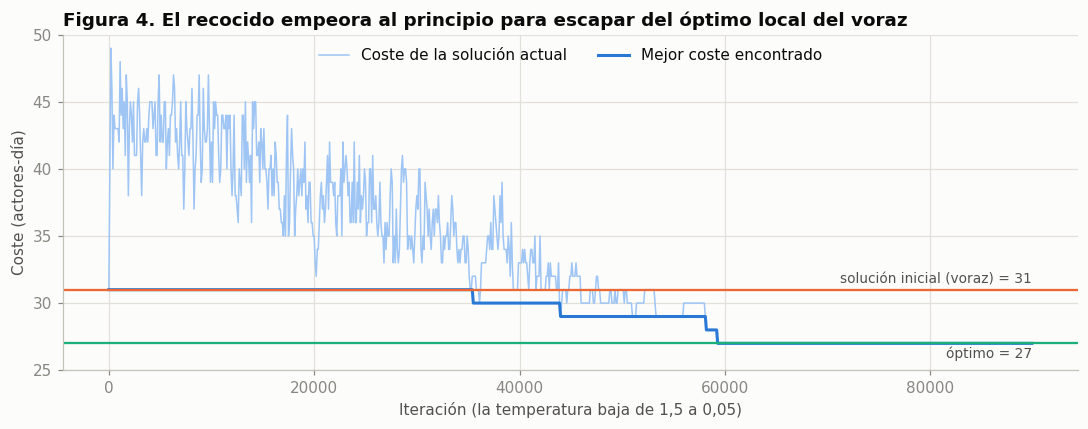

In [13]:
# Figura 4. Evolucion del recocido simulado en una ejecucion sobre el problema real.

_, _, historial = recocido_simulado(MASC, N_ACTORES, MAX_TOMAS_DIA, plan_voraz, semilla=1, guardar_historial=True)
its = [h[0] for h in historial]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(its, [h[1] for h in historial], color="#9ec5f4", linewidth=1, label="Coste de la solución actual")
ax.plot(its, [h[2] for h in historial], color=C_RECOCIDO, linewidth=2, label="Mejor coste encontrado")
ax.axhline(COSTE_OPTIMO, color=C_BYP, linewidth=1.5)
ax.text(its[-1], COSTE_OPTIMO - 0.25, f"óptimo = {COSTE_OPTIMO}", ha="right", va="top", fontsize=9, color=C_TINTA2)
ax.axhline(COSTE_VORAZ, color=C_VORAZ, linewidth=1.5)
ax.text(its[-1], COSTE_VORAZ + 0.25, f"solución inicial (voraz) = {COSTE_VORAZ}", ha="right", va="bottom",
        fontsize=9, color=C_TINTA2)
ax.set_xlabel("Iteración (la temperatura baja de 1,5 a 0,05)")
ax.set_ylabel("Coste (actores-día)")
ax.set_ylim(COSTE_OPTIMO - 2, max(h[1] for h in historial) + 1)
ax.legend(loc="upper center", ncol=2)
ax.set_title("Figura 4. El recocido empeora al principio para escapar del óptimo local del voraz")
plt.tight_layout()
plt.show()

**Lectura de la figura 4.** Al principio la temperatura es alta y el algoritmo acepta muchos empeoramientos: el coste actual sube por encima del de la solución voraz de partida. Eso es lo que le permite abandonar el óptimo local en el que el voraz se queda atrapado. A medida que la temperatura baja, acepta cada vez menos empeoramientos y la solución se estabiliza en el óptimo.

Como es un algoritmo aleatorio, no todas las ejecuciones terminan igual: de 20 ejecuciones de una sola pasada, 18 alcanzan el coste 27 y 2 se quedan en 28. Por eso la versión final hace 3 reinicios y conserva el mejor resultado.

### Comparativa con la fuerza bruta: ¿a qué distancia del óptimo queda cada propuesta?

La fuerza bruta no puede resolver el problema de 30 tomas, pero sí versiones reducidas, y en ellas da el óptimo con total seguridad. Se hacen dos experimentos con datos del problema real:

1. **Versiones reducidas de tamaño creciente**: las n primeras tomas (n de 6 a 12) con un máximo de 3 tomas por día, para que la versión reducida conserve la estructura del problema (varios días, capacidad limitada).
2. **40 versiones reducidas elegidas al azar**: 10 tomas tomadas al azar de las 30, con un máximo de 3 por día.

En ambos se compara el óptimo de la fuerza bruta con el resultado de cada propuesta. La diferencia se expresa en actores-día y en porcentaje sobre el óptimo.

In [14]:
# Experimento 1. Versiones reducidas de tamaño creciente (n primeras tomas, maximo 3 por dia).

CAP_REDUCIDA = 3
tabla_reducida = []     # (n, optimo FB, evaluadas FB, t FB, coste voraz, voraz multi, recocido, ByP, nodos ByP, t ByP)

for n in range(6, 13):
    m = MASC[:n]
    inicio = time.perf_counter()
    _, c_fb, evaluadas = fuerza_bruta(m, CAP_REDUCIDA)
    t_fb = time.perf_counter() - inicio
    c_v = coste(voraz(m, CAP_REDUCIDA), m)
    plan_vm, c_vm = voraz_multiarranque(m, CAP_REDUCIDA)
    _, c_rs = recocido_con_reinicios(m, N_ACTORES, CAP_REDUCIDA)
    inicio = time.perf_counter()
    _, c_byp, nodos, _ = ramificacion_y_poda(m, N_ACTORES, CAP_REDUCIDA, plan_inicial=plan_vm)
    t_byp = time.perf_counter() - inicio
    tabla_reducida.append((n, c_fb, evaluadas, t_fb, c_v, c_vm, c_rs, c_byp, nodos, t_byp))

print("         FUERZA BRUTA (referencia)        |        coste obtenido por cada propuesta")
print(" n | optimo | soluciones evaluadas | t (s) | voraz | voraz multi | recocido | ramif. y poda | nodos RyP")
print("---+--------+----------------------+-------+-------+-------------+----------+---------------+----------")
for n, c_fb, ev, t_fb, c_v, c_vm, c_rs, c_byp, nodos, t_byp in tabla_reducida:
    print(f"{n:2d} | {c_fb:6d} | {miles(ev):>20} | {t_fb:5.2f} | {c_v:5d} | {c_vm:11d} | {c_rs:8d} | {c_byp:13d} | {nodos:8d}")

print()
print("Distancia al optimo de la fuerza bruta (suma de las 7 versiones reducidas):")
total_opt = sum(f[1] for f in tabla_reducida)
for nombre, col in (("voraz", 4), ("voraz multiarranque", 5), ("recocido simulado", 6), ("ramificacion y poda", 7)):
    exceso = sum(f[col] - f[1] for f in tabla_reducida)
    aciertos = sum(1 for f in tabla_reducida if f[col] == f[1])
    print(f"  {nombre:20s}: +{exceso} actores-dia ({100 * exceso / total_opt:4.1f} %) | optimo en {aciertos} de {len(tabla_reducida)}")

         FUERZA BRUTA (referencia)        |        coste obtenido por cada propuesta
 n | optimo | soluciones evaluadas | t (s) | voraz | voraz multi | recocido | ramif. y poda | nodos RyP
---+--------+----------------------+-------+-------+-------------+----------+---------------+----------
 6 |     11 |                  166 |  0.00 |    11 |          11 |       11 |            11 |        6
 7 |     14 |                  652 |  0.00 |    15 |          14 |       14 |            14 |       53
 8 |     16 |                2.780 |  0.01 |    16 |          16 |       16 |            16 |      116
 9 |     16 |               12.644 |  0.04 |    16 |          16 |       16 |            16 |       60
10 |     19 |               61.136 |  0.20 |    20 |          20 |       19 |            19 |      339
11 |     20 |              312.676 |  1.15 |    20 |          20 |       20 |            20 |      136
12 |     22 |            1.680.592 |  7.20 |    23 |          23 |       22 |            

In [15]:
# Experimento 2. 40 versiones reducidas al azar (10 tomas de las 30, maximo 3 por dia) frente a la fuerza bruta.

rng = random.Random(2024)
N_MUESTRAS = 40
excesos = {"Voraz": [], "Voraz multiarranque": [], "Recocido simulado": [], "Ramificación y poda": []}
optimos = []

for _ in range(N_MUESTRAS):
    m = [MASC[t] for t in rng.sample(range(N_TOMAS), 10)]
    _, c_fb, _ = fuerza_bruta(m, CAP_REDUCIDA)                 # optimo de referencia
    optimos.append(c_fb)
    plan_vm, c_vm = voraz_multiarranque(m, CAP_REDUCIDA)
    excesos["Voraz"].append(coste(voraz(m, CAP_REDUCIDA), m) - c_fb)
    excesos["Voraz multiarranque"].append(c_vm - c_fb)
    excesos["Recocido simulado"].append(recocido_con_reinicios(m, N_ACTORES, CAP_REDUCIDA)[1] - c_fb)
    excesos["Ramificación y poda"].append(ramificacion_y_poda(m, N_ACTORES, CAP_REDUCIDA, plan_inicial=plan_vm)[1] - c_fb)

print(f"{N_MUESTRAS} versiones reducidas al azar (optimo medio por fuerza bruta: {sum(optimos) / N_MUESTRAS:.1f})")
print()
print("metodo               | alcanza el optimo | exceso medio | exceso medio (%) | peor caso")
print("---------------------+-------------------+--------------+------------------+----------")
for nombre, lista in excesos.items():
    aciertos = sum(1 for e in lista if e == 0)
    medio = sum(lista) / N_MUESTRAS
    medio_pct = 100 * sum(e / o for e, o in zip(lista, optimos)) / N_MUESTRAS
    print(f"{nombre:20s} | {aciertos:8d} de {N_MUESTRAS:<5d} | {medio:12.2f} | {medio_pct:16.1f} | +{max(lista)}")

40 versiones reducidas al azar (optimo medio por fuerza bruta: 17.1)

metodo               | alcanza el optimo | exceso medio | exceso medio (%) | peor caso
---------------------+-------------------+--------------+------------------+----------
Voraz                |        2 de 40    |         1.90 |             11.1 | +5
Voraz multiarranque  |       12 de 40    |         0.93 |              5.4 | +3
Recocido simulado    |       40 de 40    |         0.00 |              0.0 | +0
Ramificación y poda  |       40 de 40    |         0.00 |              0.0 | +0


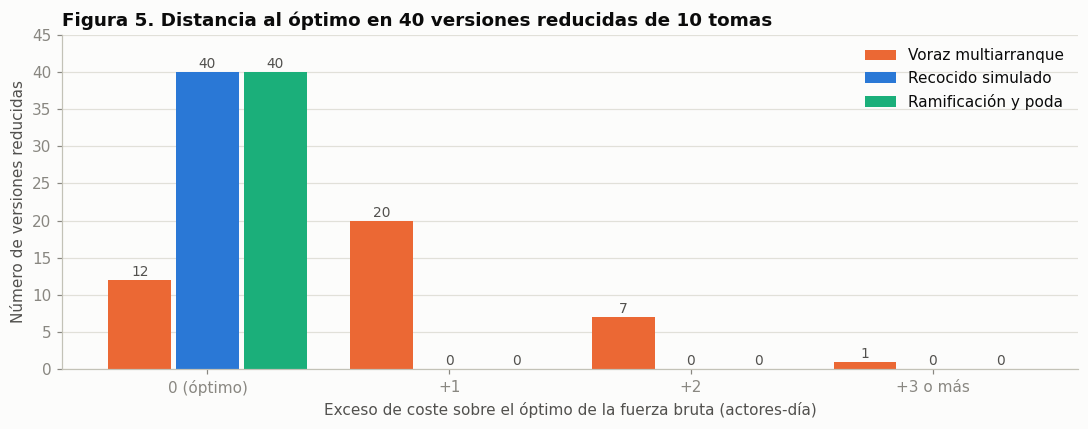

In [16]:
# Figura 5. Distancia al optimo de la fuerza bruta en las 40 versiones reducidas.

categorias = [0, 1, 2, 3]                       # exceso sobre el optimo: 0, +1, +2, +3 o mas
etiquetas = ["0 (óptimo)", "+1", "+2", "+3 o más"]
series = [("Voraz multiarranque", C_VORAZ), ("Recocido simulado", C_RECOCIDO), ("Ramificación y poda", C_BYP)]
ancho = 0.26

fig, ax = plt.subplots(figsize=(10, 4))
for k, (nombre, color) in enumerate(series):
    cuentas = [sum(1 for e in excesos[nombre] if min(e, 3) == c) for c in categorias]
    xs = [c + (k - 1) * (ancho + 0.02) for c in categorias]
    ax.bar(xs, cuentas, width=ancho, color=color, label=nombre)
    for x, v in zip(xs, cuentas):
        ax.text(x, v + 0.5, str(v), ha="center", fontsize=9, color=C_TINTA2)
ax.set_xticks(categorias)
ax.set_xticklabels(etiquetas)
ax.set_xlabel("Exceso de coste sobre el óptimo de la fuerza bruta (actores-día)")
ax.set_ylabel("Número de versiones reducidas")
ax.set_ylim(0, N_MUESTRAS + 5)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Figura 5. Distancia al óptimo en 40 versiones reducidas de 10 tomas")
plt.tight_layout()
plt.show()

**Resultado de la comparativa en versiones reducidas.**

- **Ramificación y poda** obtiene el óptimo de la fuerza bruta en todas las versiones reducidas, como corresponde a un método exacto: es la comprobación experimental de que la poda no descarta soluciones óptimas. Lo consigue explorando unos cientos de nodos donde la fuerza bruta evalúa hasta 1,7 millones de soluciones.
- **Recocido simulado** también alcanza el óptimo en todas las versiones reducidas probadas (distancia 0).
- **Voraz con multiarranque**, la propuesta de la primera versión del trabajo, solo alcanza el óptimo en 12 de las 40 versiones al azar y se queda de media un 5,4 % por encima (hasta 3 actores-día en el peor caso). El voraz simple queda aún más lejos: un 11,1 % de media.

### Resultado sobre el problema completo (30 tomas)

En el problema completo la fuerza bruta no es ejecutable, pero la referencia del óptimo la proporciona la ramificación y poda, que es exacta y ha completado la búsqueda. La figura 6 resume el coste de cada método y la figura 7 muestra la planificación óptima.

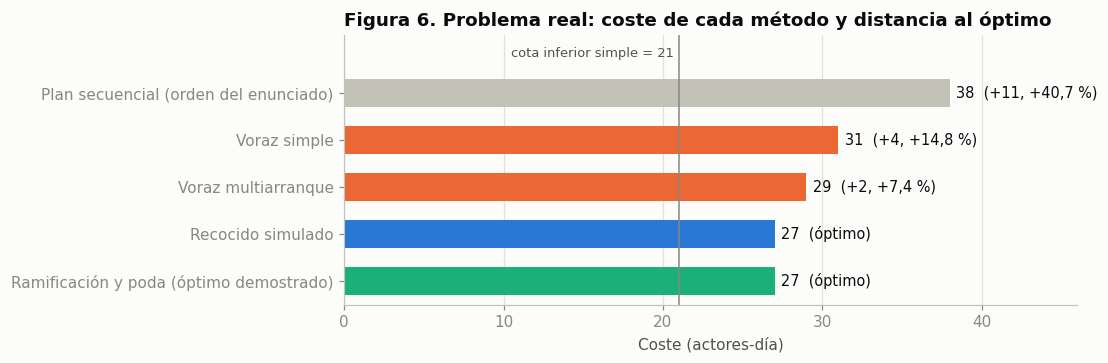

Distancia al optimo demostrado en el problema completo:
  Plan secuencial (orden del enunciado)       38  ->  +11 (40.7 %)
  Voraz simple                                31  ->  +4 (14.8 %)
  Voraz multiarranque                         29  ->  +2 (7.4 %)
  Recocido simulado                           27  ->  +0 (0.0 %)
  Ramificación y poda (óptimo demostrado)     27  ->  +0 (0.0 %)


In [17]:
# Figura 6. Coste de cada metodo en el problema real y distancia al optimo demostrado.

cota = cota_inferior_simple(MASC, N_ACTORES, MAX_TOMAS_DIA)
metodos = [
    ("Plan secuencial (orden del enunciado)", COSTE_SECUENCIAL, C_NEUTRO),
    ("Voraz simple", COSTE_VORAZ, C_VORAZ),
    ("Voraz multiarranque", COSTE_VORAZ_MULTI, C_VORAZ),
    ("Recocido simulado", COSTE_RS, C_RECOCIDO),
    ("Ramificación y poda (óptimo demostrado)", COSTE_OPTIMO, C_BYP),
]

fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (nombre, valor, color) in enumerate(metodos):
    ax.barh(i, valor, color=color, height=0.6)
    exceso = valor - COSTE_OPTIMO
    porcentaje = f"{100 * exceso / COSTE_OPTIMO:.1f}".replace(".", ",")
    texto = f"{valor}  (óptimo)" if exceso == 0 else f"{valor}  (+{exceso}, +{porcentaje} %)"
    ax.text(valor + 0.4, i, texto, va="center", fontsize=9.5, color=C_TINTA)
ax.axvline(cota, color=C_SUAVE, linewidth=1)
ax.text(cota - 0.3, -0.85, f"cota inferior simple = {cota}", ha="right", va="center", fontsize=8.5, color=C_TINTA2)
ax.set_yticks(range(len(metodos)))
ax.set_yticklabels([m[0] for m in metodos])
ax.invert_yaxis()
ax.set_ylim(len(metodos) - 0.5, -1.25)
ax.set_xlim(0, COSTE_SECUENCIAL + 8)
ax.set_xlabel("Coste (actores-día)")
ax.grid(axis="y", visible=False)
ax.set_title("Figura 6. Problema real: coste de cada método y distancia al óptimo")
plt.tight_layout()
plt.show()

print("Distancia al optimo demostrado en el problema completo:")
for nombre, valor, _ in metodos:
    print(f"  {nombre:42s} {valor:3d}  ->  +{valor - COSTE_OPTIMO} ({100 * (valor - COSTE_OPTIMO) / COSTE_OPTIMO:.1f} %)")

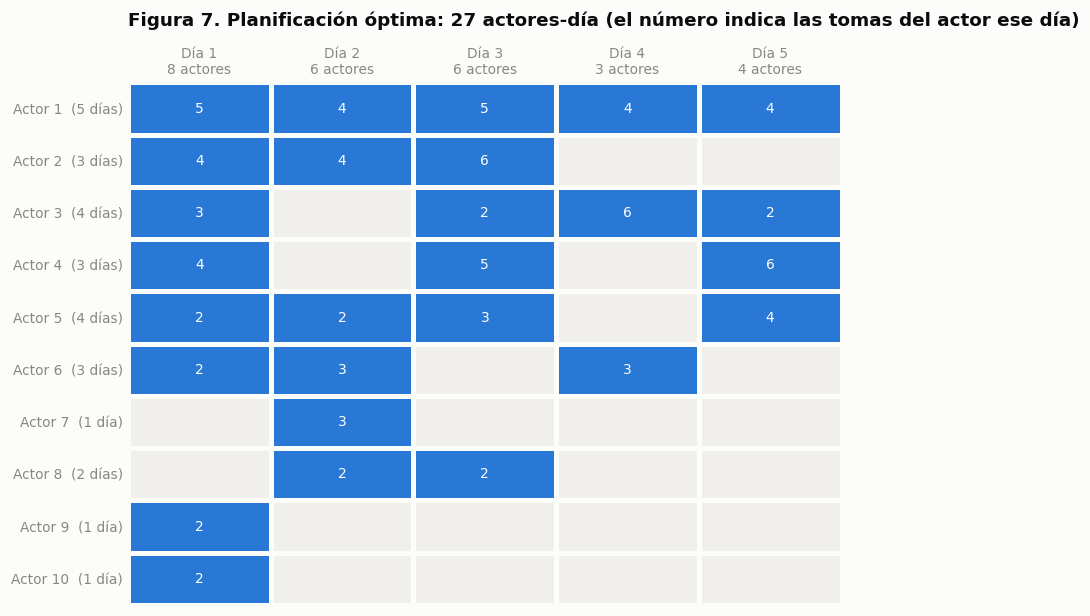

PLANIFICACION OPTIMA
  Dia 1: tomas [1, 10, 12, 16, 25, 26]
  Dia 2: tomas [3, 4, 8, 15, 21, 29]
  Dia 3: tomas [5, 6, 7, 9, 11, 22]
  Dia 4: tomas [14, 17, 18, 19, 23, 24]
  Dia 5: tomas [2, 13, 20, 27, 28, 30]


In [18]:
# Figura 7. Planificacion optima: que actores acuden cada dia y cuantas tomas graba cada uno.

def dibuja_plan(plan, masc, n_actores, titulo):
    n_dias = len(plan)
    # veces[a][d] = numero de tomas del dia d en las que interviene el actor a
    veces = [[sum((masc[t] >> a) & 1 for t in dia) for dia in plan] for a in range(n_actores)]
    presente = [[1 if v else 0 for v in fila] for fila in veces]
    fig, ax = plt.subplots(figsize=(1.6 + 1.25 * n_dias, 0.42 * n_actores + 1.5))
    ax.pcolormesh(presente, cmap=ListedColormap(["#f0efec", C_RECOCIDO]), vmin=0, vmax=1,
                  edgecolors=C_FONDO, linewidth=3)
    ax.invert_yaxis()
    for a in range(n_actores):
        for d in range(n_dias):
            if veces[a][d]:
                ax.text(d + 0.5, a + 0.5, str(veces[a][d]), ha="center", va="center", color="white", fontsize=9)
    ax.set_xticks([d + 0.5 for d in range(n_dias)])
    ax.set_xticklabels([f"Día {d + 1}\n{sum(presente[a][d] for a in range(n_actores))} actores"
                        for d in range(n_dias)], fontsize=9)
    ax.set_yticks([a + 0.5 for a in range(n_actores)])
    ax.set_yticklabels([f"Actor {a + 1}  ({sum(presente[a])} {'día' if sum(presente[a]) == 1 else 'días'})"
                        for a in range(n_actores)], fontsize=9)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_title(titulo, pad=14)
    plt.tight_layout()
    plt.show()

dibuja_plan(plan_byp, MASC, N_ACTORES,
            f"Figura 7. Planificación óptima: {COSTE_OPTIMO} actores-día (el número indica las tomas del actor ese día)")
print("PLANIFICACION OPTIMA")
for i, dia in enumerate(plan_byp, 1):
    print(f"  Dia {i}: tomas {[t + 1 for t in dia]}")

**Conclusión del apartado.** En el problema real, el óptimo es **27 actores-día** y queda demostrado por la ramificación y poda. El recocido simulado alcanza ese mismo valor en menos de un segundo. La propuesta voraz de la primera versión (29) se quedaba a 2 actores-día del óptimo, un 7,4 %. La cota inferior simple (21) no es alcanzable: es una cota válida pero poco ajustada, y por eso la ramificación y poda necesita la cota más fina que se recalcula en cada nodo.

(*)Calcula la complejidad del algoritmo

Respuesta

Notación: n tomas, m actores, capacidad c (tomas por día), D días abiertos (D ≤ n).

**Voraz.** Coloca n tomas; para cada una recorre las pendientes (hasta n) y cuenta los actores nuevos (m bits): **O(n² · m)**. Con multiarranque se repite n veces: **O(n³ · m)**.

**Ramificación y poda.**
- Trabajo por nodo: la cota inferior recorre los m actores y los D días, O(m · D); probar los días candidatos cuesta O(D log D). En total O(m · n) por nodo en el peor caso.
- Número de nodos: en el peor caso la poda no descarta nada y se recorre el mismo árbol que la fuerza bruta, así que la complejidad en el peor caso sigue siendo superexponencial, **O(m · n · P(n))**.
- La mejora es **empírica, no asintótica**: lo que se reduce es el número de nodos realmente visitados. En el problema real se visitan del orden de 10⁵ nodos frente a 7,26 · 10²³ soluciones. La celda siguiente mide esa reducción y el efecto de la heurística de ordenación.

**Recocido simulado.**
- Cada iteración quita y pone una o dos tomas: solo toca los actores de esas tomas, **O(m)** por iteración (como mucho 4m operaciones).
- Con I iteraciones y R reinicios, más la solución voraz inicial de cada reinicio: **O(R · (n² · m + I · m))**.
- En este trabajo I = 3000 · n y R = 3, por lo que el coste total es **O(n² · m)**: polinómico. El número de iteraciones es una decisión de diseño que no depende del tamaño del espacio de soluciones.

**Comparación.**

| Algoritmo | Complejidad | Óptimo garantizado |
|---|---|---|
| Fuerza bruta | O(n · P(n)), superexponencial | sí |
| Ramificación y poda | O(m · n · P(n)) en el peor caso; mucho menor en la práctica | sí |
| Voraz multiarranque | O(n³ · m) | no |
| Recocido simulado | O(n² · m) con los parámetros usados | no |

In [19]:
# Medida empirica: nodos de la ramificacion y poda frente a soluciones de la fuerza bruta,
# y efecto de la heuristica de ordenacion en el problema real.

print("Problema real (30 tomas): efecto de la heuristica de ordenacion en la ramificacion y poda")
print("orden de colocacion de las tomas       | nodos explorados | optimo demostrado | coste | tiempo (s)")
print("---------------------------------------+------------------+-------------------+-------+-----------")
LIMITE = 2_000_000
for nombre, orden in (("actores poco frecuentes (propuesto)", "poco_frecuentes"),
                      ("orden original del enunciado", "original"),
                      ("tomas con mas actores primero", "mas_actores")):
    inicio = time.perf_counter()
    _, c, nodos, completo = ramificacion_y_poda(MASC, N_ACTORES, MAX_TOMAS_DIA, plan_inicial=plan_voraz_multi,
                                               max_nodos=LIMITE, orden=orden)
    segundos = time.perf_counter() - inicio
    texto_nodos = miles(nodos) if completo else f"> {miles(LIMITE)}"
    print(f"{nombre:38s} | {texto_nodos:>16} | {str(completo):>17} | {c:5d} | {segundos:9.2f}")
print(f"(busqueda limitada a {miles(LIMITE)} nodos; si se alcanza el limite no hay demostracion de optimalidad)")

Problema real (30 tomas): efecto de la heuristica de ordenacion en la ramificacion y poda
orden de colocacion de las tomas       | nodos explorados | optimo demostrado | coste | tiempo (s)
---------------------------------------+------------------+-------------------+-------+-----------
actores poco frecuentes (propuesto)    |           74.598 |              True |    27 |      0.44
orden original del enunciado           |      > 2.000.000 |             False |    27 |     13.95
tomas con mas actores primero          |      > 2.000.000 |             False |    27 |     16.97
(busqueda limitada a 2.000.000 nodos; si se alcanza el limite no hay demostracion de optimalidad)


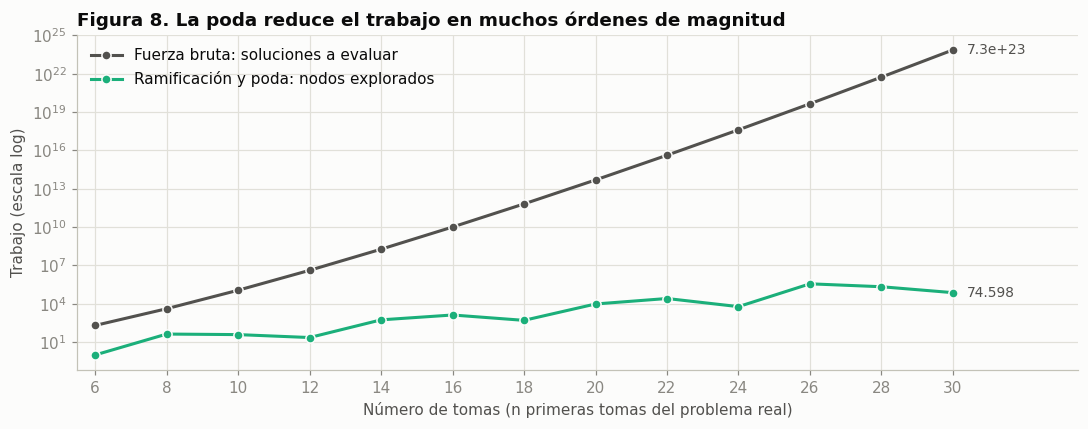

 n | fuerza bruta (soluciones) | ramificacion y poda (nodos)
 6 |                 2.030e+02 |            1
 8 |                 4.131e+03 |           43
10 |                 1.153e+05 |           39
12 |                 4.164e+06 |           23
14 |                 1.872e+08 |          556
16 |                 1.017e+10 |        1.334
18 |                 6.543e+11 |          508
20 |                 4.893e+13 |        9.687
22 |                 4.196e+15 |       26.005
24 |                 4.079e+17 |        6.016
26 |                 4.452e+19 |      366.831
28 |                 5.409e+21 |      216.523
30 |                 7.264e+23 |       74.598


In [20]:
# Figura 8. Trabajo realizado por cada algoritmo exacto al crecer el problema (escala logaritmica).
# Versiones reducidas del problema real con la capacidad real (6 tomas por dia).

tamanos = list(range(6, 31, 2))
soluciones_fb = [float(particiones_validas(n, MAX_TOMAS_DIA)) for n in tamanos]
nodos_byp = []
for n in tamanos:
    m = MASC[:n]
    plan_vm, _ = voraz_multiarranque(m, MAX_TOMAS_DIA)
    nodos_byp.append(ramificacion_y_poda(m, N_ACTORES, MAX_TOMAS_DIA, plan_inicial=plan_vm)[2])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tamanos, soluciones_fb, "o-", color=C_FB, markersize=6, markeredgecolor=C_FONDO,
        label="Fuerza bruta: soluciones a evaluar")
ax.plot(tamanos, nodos_byp, "o-", color=C_BYP, markersize=6, markeredgecolor=C_FONDO,
        label="Ramificación y poda: nodos explorados")
ax.text(30.4, soluciones_fb[-1], f"{soluciones_fb[-1]:.1e}", va="center", fontsize=9, color=C_TINTA2)
ax.text(30.4, nodos_byp[-1], miles(nodos_byp[-1]), va="center", fontsize=9, color=C_TINTA2)
ax.set_yscale("log")
ax.set_xticks(tamanos)
ax.set_xlim(5.5, 33.5)
ax.set_xlabel("Número de tomas (n primeras tomas del problema real)")
ax.set_ylabel("Trabajo (escala log)")
ax.legend(loc="upper left")
ax.set_title("Figura 8. La poda reduce el trabajo en muchos órdenes de magnitud")
plt.tight_layout()
plt.show()

print(" n | fuerza bruta (soluciones) | ramificacion y poda (nodos)")
for n, s, nd in zip(tamanos, soluciones_fb, nodos_byp):
    print(f"{n:2d} | {s:25.3e} | {miles(nd):>12}")

**Lectura de la figura 8.** La fuerza bruta crece de forma regular y superexponencial. La ramificación y poda se mantiene más de 14 órdenes de magnitud por debajo a partir de 24 tomas (19 en el problema completo), pero su trabajo no crece de forma regular: depende de lo ajustada que resulte la cota en cada instancia (la versión de 26 tomas le cuesta más que la de 30). Es el comportamiento típico de un método exacto con poda: muy eficaz en la práctica, pero sin garantía sobre el número de nodos.

Según el problema (y tenga sentido), diseña un juego de datos de entrada aleatorios

Respuesta

El generador produce una matriz binaria de tomas por actores con dos perfiles:

- **Perfil uniforme**: cada actor participa en cada toma con la misma probabilidad p. Es el caso más sencillo, pero se parece poco a un doblaje real.
- **Perfil "protagonistas"**: imita lo que se observa en los datos reales (figura 1), donde unos pocos actores aparecen en casi todas las tomas y otros en muy pocas. La probabilidad de participación del actor a es `p_max · r^a`: decrece de forma geométrica del primer actor al último. Con p_max = 0,7 y r = 0,78 las frecuencias resultantes son parecidas a las del enunciado.

En ambos casos se garantiza que ninguna toma queda sin actores, porque una toma vacía no tiene sentido. El generador es parametrizable (número de tomas, número de actores, probabilidades y semilla), de modo que sirve tanto para crear versiones reducidas que la fuerza bruta puede resolver como para crear instancias mayores que el problema real. La semilla hace que los experimentos sean reproducibles.

In [21]:
# Generador de juegos de datos aleatorios.

def genera_datos(n_tomas, n_actores, perfil="protagonistas", prob=0.3, p_max=0.7, r=0.78, semilla=None):
    """perfil='uniforme': todos los actores con probabilidad 'prob'.
    perfil='protagonistas': el actor a participa con probabilidad p_max * r**a (decreciente)."""
    rng = random.Random(semilla)
    if perfil == "uniforme":
        probabilidades = [prob] * n_actores
    else:
        probabilidades = [p_max * r ** a for a in range(n_actores)]
    matriz = []
    for _ in range(n_tomas):
        fila = [1 if rng.random() < probabilidades[a] else 0 for a in range(n_actores)]
        if sum(fila) == 0:                          # ninguna toma puede quedar sin actores
            fila[rng.randrange(n_actores)] = 1
        matriz.append(fila)
    return matriz

datos_ejemplo = genera_datos(30, 10, semilla=7)
print("Juego de datos aleatorio (perfil 'protagonistas', 30 tomas x 10 actores). Primeras 6 tomas:")
for i, fila in enumerate(datos_ejemplo[:6], 1):
    print(f"  Toma {i} -> {fila}")
print("Tomas por actor en los datos generados:", [sum(f[a] for f in datos_ejemplo) for a in range(10)])
print("Tomas por actor en los datos reales   :", tomas_por_actor)

Juego de datos aleatorio (perfil 'protagonistas', 30 tomas x 10 actores). Primeras 6 tomas:
  Toma 1 -> [1, 1, 0, 1, 0, 0, 1, 0, 1, 0]
  Toma 2 -> [1, 1, 1, 0, 1, 0, 0, 0, 0, 0]
  Toma 3 -> [0, 1, 0, 1, 1, 1, 0, 0, 0, 0]
  Toma 4 -> [1, 1, 0, 1, 1, 0, 0, 0, 0, 0]
  Toma 5 -> [1, 1, 0, 0, 1, 0, 0, 0, 0, 0]
  Toma 6 -> [0, 1, 1, 0, 1, 0, 1, 0, 0, 0]
Tomas por actor en los datos generados: [19, 21, 14, 5, 10, 6, 9, 3, 3, 2]
Tomas por actor en los datos reales   : [22, 14, 13, 15, 11, 8, 3, 4, 2, 2]


Aplica el algoritmo al juego de datos generado

Respuesta

Se aplican los algoritmos a datos aleatorios en tres experimentos:

1. **Instancias reducidas aleatorias frente a la fuerza bruta** (40 instancias de 10 tomas y 6 actores, máximo 3 por día): repite la comparativa con el óptimo, ahora con datos que no son los del enunciado.
2. **Una instancia aleatoria del mismo tamaño que el problema real** (30 tomas, 10 actores, 6 por día).
3. **Escalabilidad**: instancias de 10 a 60 tomas, para ver hasta dónde llega el método exacto y cómo se comporta el recocido cuando el exacto ya no termina. La ramificación y poda se limita a 1.000.000 de nodos; si alcanza el límite, su resultado deja de estar demostrado como óptimo.

In [22]:
# Experimento 3. Instancias reducidas aleatorias (10 tomas, 6 actores, maximo 3 por dia) frente a la fuerza bruta.

N_INST = 40
excesos_rnd = {"Voraz": [], "Voraz multiarranque": [], "Recocido simulado": [], "Ramificación y poda": []}
optimos_rnd = []
for s in range(N_INST):
    perfil = "protagonistas" if s % 2 == 0 else "uniforme"          # mitad de cada perfil
    m = a_mascaras(genera_datos(10, 6, perfil=perfil, prob=0.35, semilla=1000 + s))
    _, c_fb, _ = fuerza_bruta(m, 3)
    optimos_rnd.append(c_fb)
    plan_vm, c_vm = voraz_multiarranque(m, 3)
    excesos_rnd["Voraz"].append(coste(voraz(m, 3), m) - c_fb)
    excesos_rnd["Voraz multiarranque"].append(c_vm - c_fb)
    excesos_rnd["Recocido simulado"].append(recocido_con_reinicios(m, 6, 3)[1] - c_fb)
    excesos_rnd["Ramificación y poda"].append(ramificacion_y_poda(m, 6, 3, plan_inicial=plan_vm)[1] - c_fb)

print(f"{N_INST} instancias aleatorias reducidas (optimo medio por fuerza bruta: {sum(optimos_rnd) / N_INST:.1f})")
print()
print("metodo               | alcanza el optimo | exceso medio | exceso medio (%) | peor caso")
print("---------------------+-------------------+--------------+------------------+----------")
for nombre, lista in excesos_rnd.items():
    aciertos = sum(1 for e in lista if e == 0)
    medio = sum(lista) / N_INST
    medio_pct = 100 * sum(e / o for e, o in zip(lista, optimos_rnd)) / N_INST
    print(f"{nombre:20s} | {aciertos:8d} de {N_INST:<5d} | {medio:12.2f} | {medio_pct:16.1f} | +{max(lista)}")

40 instancias aleatorias reducidas (optimo medio por fuerza bruta: 12.2)

metodo               | alcanza el optimo | exceso medio | exceso medio (%) | peor caso
---------------------+-------------------+--------------+------------------+----------
Voraz                |        2 de 40    |         1.95 |             16.1 | +5
Voraz multiarranque  |       11 de 40    |         1.00 |              8.3 | +3
Recocido simulado    |       40 de 40    |         0.00 |              0.0 | +0
Ramificación y poda  |       40 de 40    |         0.00 |              0.0 | +0


In [23]:
# Experimento 4. Una instancia aleatoria del tamaño del problema real (30 tomas, 10 actores, 6 por dia).

matriz_rnd = genera_datos(30, 10, semilla=7)
m_rnd = a_mascaras(matriz_rnd)

plan_vm, c_vm = voraz_multiarranque(m_rnd, 6)
inicio = time.perf_counter()
plan_rs_rnd, c_rs = recocido_con_reinicios(m_rnd, 10, 6)
t_rs = time.perf_counter() - inicio
inicio = time.perf_counter()
plan_opt_rnd, c_opt, nodos, completo = ramificacion_y_poda(m_rnd, 10, 6, plan_inicial=plan_rs_rnd, max_nodos=3_000_000)
t_byp = time.perf_counter() - inicio

print("INSTANCIA ALEATORIA DE 30 TOMAS (perfil 'protagonistas', semilla 7)")
print(f"  Voraz multiarranque : coste {c_vm}")
print(f"  Recocido simulado   : coste {c_rs}   ({t_rs:.2f} s)")
print(f"  Ramificacion y poda : coste {c_opt}   ({miles(nodos)} nodos, {t_byp:.2f} s, optimo demostrado: {completo})")
print()
print("Planificacion obtenida por el recocido simulado:")
for i, dia in enumerate(plan_rs_rnd, 1):
    actores = actores_de(mascara_del_dia(dia, m_rnd))
    print(f"  Dia {i} -> tomas {[t + 1 for t in dia]} -> actores {actores} ({len(actores)})")
print("Plan valido:", es_valido(plan_rs_rnd, 30, 6))

INSTANCIA ALEATORIA DE 30 TOMAS (perfil 'protagonistas', semilla 7)
  Voraz multiarranque : coste 30
  Recocido simulado   : coste 27   (0.80 s)
  Ramificacion y poda : coste 27   (121.131 nodos, 0.70 s, optimo demostrado: True)

Planificacion obtenida por el recocido simulado:
  Dia 1 -> tomas [7, 10, 21, 24, 28, 29] -> actores [1, 2] (2)
  Dia 2 -> tomas [1, 6, 8, 9, 11, 30] -> actores [1, 2, 3, 4, 5, 7, 9] (7)
  Dia 3 -> tomas [2, 5, 14, 17, 19, 25] -> actores [1, 2, 3, 5] (4)
  Dia 4 -> tomas [15, 16, 22, 23, 26, 27] -> actores [1, 2, 3, 4, 6, 7, 8] (7)
  Dia 5 -> tomas [3, 4, 12, 13, 18, 20] -> actores [1, 2, 3, 4, 5, 6, 10] (7)
Plan valido: True


In [24]:
# Experimento 5. Escalabilidad: instancias aleatorias de 10 a 60 tomas (10 actores, 6 tomas por dia).

MAX_NODOS = 1_000_000
escala = []    # (n, voraz multi, recocido, t recocido, ByP, nodos, demostrado, t ByP)
for n in (10, 15, 20, 25, 30, 40, 50, 60):
    m = a_mascaras(genera_datos(n, 10, semilla=n))
    _, c_vm = voraz_multiarranque(m, 6)
    inicio = time.perf_counter()
    plan_rs_n, c_rs = recocido_con_reinicios(m, 10, 6)
    t_rs = time.perf_counter() - inicio
    inicio = time.perf_counter()
    _, c_byp, nodos, completo = ramificacion_y_poda(m, 10, 6, plan_inicial=plan_rs_n, max_nodos=MAX_NODOS)
    t_byp = time.perf_counter() - inicio
    escala.append((n, c_vm, c_rs, t_rs, c_byp, nodos, completo, t_byp))

print("     |   voraz   |     recocido      |              ramificacion y poda")
print("  n  |   multi   | coste | tiempo(s) | coste |     nodos | tiempo(s) | resultado")
print("-----+-----------+-------+-----------+-------+-----------+-----------+---------------------------")
for n, c_vm, c_rs, t_rs, c_byp, nodos, completo, t_byp in escala:
    estado = "optimo demostrado" if completo else "limite de nodos (sin garantia)"
    print(f"{n:4d} | {c_vm:9d} | {c_rs:5d} | {t_rs:9.2f} | {c_byp:5d} | {min(nodos, MAX_NODOS):9d} | {t_byp:9.2f} | {estado}")

     |   voraz   |     recocido      |              ramificacion y poda
  n  |   multi   | coste | tiempo(s) | coste |     nodos | tiempo(s) | resultado
-----+-----------+-------+-----------+-------+-----------+-----------+---------------------------
  10 |        13 |    13 |      0.40 |    13 |        11 |      0.00 | optimo demostrado
  15 |        16 |    15 |      0.36 |    15 |       367 |      0.00 | optimo demostrado
  20 |        21 |    19 |      0.54 |    19 |      3847 |      0.02 | optimo demostrado
  25 |        29 |    25 |      0.71 |    25 |     50840 |      0.28 | optimo demostrado
  30 |        26 |    25 |      0.74 |    25 |    135488 |      0.71 | optimo demostrado
  40 |        39 |    34 |      1.10 |    34 |   1000000 |      5.61 | limite de nodos (sin garantia)
  50 |        47 |    40 |      1.27 |    40 |   1000000 |      5.27 | limite de nodos (sin garantia)
  60 |        53 |    46 |      1.58 |    46 |   1000000 |      6.15 | limite de nodos (sin garantia

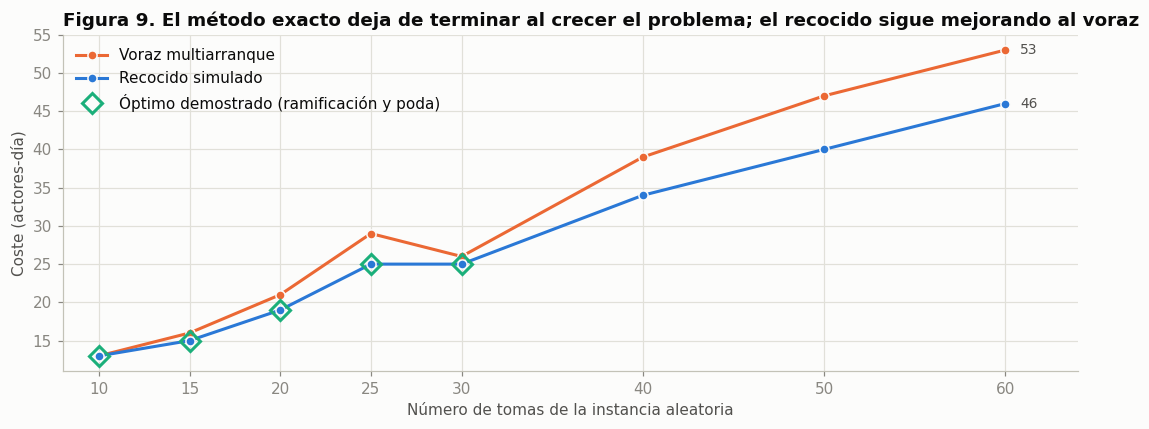

In [25]:
# Figura 9. Escalabilidad: coste obtenido por cada metodo al crecer el problema.

ns_e = [f[0] for f in escala]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ns_e, [f[1] for f in escala], "o-", color=C_VORAZ, markersize=6, markeredgecolor=C_FONDO,
        label="Voraz multiarranque")
ax.plot(ns_e, [f[2] for f in escala], "o-", color=C_RECOCIDO, markersize=6, markeredgecolor=C_FONDO,
        label="Recocido simulado")
demostrados = [(f[0], f[4]) for f in escala if f[6]]
ax.plot([d[0] for d in demostrados], [d[1] for d in demostrados], "D", color=C_BYP, markersize=9,
        markerfacecolor="none", markeredgewidth=2, label="Óptimo demostrado (ramificación y poda)")
ultimo = escala[-1]
ax.text(ultimo[0] + 0.8, ultimo[1], str(ultimo[1]), va="center", fontsize=9, color=C_TINTA2)
ax.text(ultimo[0] + 0.8, ultimo[2], str(ultimo[2]), va="center", fontsize=9, color=C_TINTA2)
ax.set_xticks(ns_e)
ax.set_xlim(8, 64)
ax.set_xlabel("Número de tomas de la instancia aleatoria")
ax.set_ylabel("Coste (actores-día)")
ax.legend(loc="upper left")
ax.set_title("Figura 9. El método exacto deja de terminar al crecer el problema; el recocido sigue mejorando al voraz")
plt.tight_layout()
plt.show()

**Resultados sobre los datos aleatorios.**

- En las 40 instancias reducidas aleatorias se repite lo observado con los datos reales: la ramificación y poda coincide siempre con la fuerza bruta, el recocido alcanza el óptimo en las 40 y el voraz con multiarranque solo en 11, con un exceso medio del 8,3 %.
- En la instancia aleatoria de 30 tomas, la ramificación y poda completa la búsqueda y confirma que el resultado del recocido es óptimo.
- En el experimento de escalabilidad, la ramificación y poda demuestra el óptimo hasta 30 tomas y el recocido coincide con él en todos esos tamaños. A partir de 40 tomas la búsqueda exacta agota el límite de nodos sin terminar: es el comportamiento exponencial esperado. El recocido sigue resolviendo en un segundo aproximadamente e iguala o mejora al voraz en todos los tamaños, con una diferencia que crece con el tamaño del problema (7 actores-día en 50 y 60 tomas).
- Limitación: para 40 tomas o más no se conoce el óptimo, así que en esos tamaños solo se puede afirmar que el recocido mejora al voraz, no a qué distancia queda del óptimo.

Enumera las referencias que has utilizado(si ha sido necesario) para llevar a cabo el trabajo

Respuesta

1. Material de la asignatura Algoritmos de Optimización: análisis de la complejidad, algoritmos voraces, técnicas de búsqueda en árboles y metaheurísticas.
2. Brassard, G. y Bratley, P. (1997). *Fundamentos de algoritmia*. Prentice Hall. (Vuelta atrás y ramificación y poda.)
3. Guerequeta, R. y Vallecillo, A. (2000). *Técnicas de diseño de algoritmos*. Universidad de Málaga. http://www.lcc.uma.es/~av/Libro/indice.html
4. Duarte, A. (2008). *Metaheurísticas*. Dykinson. (Recocido simulado y esquemas de multiarranque.)
5. Documentación oficial de Python (módulos `math` y `random`) y de Matplotlib.
6. Herramienta de inteligencia artificial como apoyo en la implementación del código en Python.

Describe brevemente las lineas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño

Respuesta

**Mejorar el método exacto.** La ramificación y poda deja de terminar entre 30 y 40 tomas en instancias aleatorias. Se podría llegar más lejos con cotas inferiores más ajustadas (por ejemplo, considerando parejas de actores que comparten tomas), con memorización de estados ya visitados, o formulando el problema como programación lineal entera y resolviéndolo con un solver. Una formulación prometedora es decidir directamente qué conjunto de actores se cita cada día, porque elimina la simetría entre días.

**Mejorar la metaheurística.** Ajustar de forma sistemática los parámetros del recocido (temperaturas, número de iteraciones, proporción entre los dos vecindarios), añadir vecindarios más grandes (mover un actor completo de un día a otro) o probar otras metaheurísticas de la asignatura, como algoritmos genéticos con un cruce que respete los días, o GRASP, que combina la construcción voraz aleatorizada con búsqueda local.

**Medir la calidad en tamaños grandes.** Cuando no se conoce el óptimo, la calidad de una heurística se puede acotar con una cota inferior. La cota simple usada aquí es poco ajustada (21 frente a un óptimo de 27 en el problema real); una cota mejor permitiría dar garantías del tipo "como mucho a un x % del óptimo" en instancias de 60 o 100 tomas.

**Variaciones del problema.**
- Tarifas distintas por actor: basta con ponderar cada actor en la función objetivo; los tres algoritmos se adaptan cambiando el "+1" por el coste del actor.
- Disponibilidad limitada: actores que no pueden acudir ciertos días. Los días dejan de ser intercambiables y el modelo de partición debe pasar a ser una asignación a días concretos.
- Capacidad variable por día o duración distinta de cada toma, lo que acerca el problema a los de empaquetado.
- Precedencias entre tomas o un número máximo de días de estudio.
- Varios objetivos a la vez: minimizar el coste y, a igualdad de coste, el número de días de alquiler del estudio.

**Variación al alza del tamaño.** Para una serie completa con cientos de tomas, el planteamiento razonable es el que apunta este trabajo: una metaheurística de coste polinómico para obtener la planificación, y un método exacto o una cota inferior para saber a qué distancia del óptimo se está.